In [62]:
#import libs
import polars as pl
import polars.selectors as cs
import huggingface_hub as hf
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import tqdm
import os
from datasets import load_dataset
from huggingface_hub import HfApi, login
from huggingface_hub.utils import HfHubHTTPError
import getpass
from IPython.display import display
import ipywidgets as widgets
from google.colab import data_table

In [64]:
# Enables interactive table views across the whole notebook
data_table.enable_dataframe_formatter()


In [ ]:
# from huggingface_hub import CommitOperationDelete, HfApi

# api = HfApi()
# repo_id = "gamusa/docvqa-canonical"
# branch = "three-splits"

# # 1. Inspect existing files
# tree = list(
#     api.list_repo_tree(
#         repo_id=repo_id, repo_type="dataset", revision=branch, path_in_repo="data"
#     )
# )
# all_paths = [getattr(f, "path", f) for f in tree]

# # 2. Identify the 23 stale pre-DSU shards
# stale_shards = [
#     p for p in all_paths if ("of-00019.parquet" in p or "of-00004.parquet" in p)
# ]
# print(f"Found {len(stale_shards)} stale shards to delete:")
# for s in stale_shards:
#   print(f"  • {s}")

# assert len(stale_shards) == 23, (
#     f"Expected exactly 23 stale shards, found {len(stale_shards)}!"
# )

# # 3. Purge orphaned shards in a single atomic commit
# operations = [CommitOperationDelete(path_in_repo=p) for p in stale_shards]

# api.create_commit(
#     repo_id=repo_id,
#     repo_type="dataset",
#     revision=branch,
#     operations=operations,
#     commit_message=(
#         "fix: purge 23 orphaned pre-DSU shards (keep exact 26 canonical shards)"
#     ),
#     token=hf_token,  # Or pass your HF_TOKEN
# )

# print(
#     f"\n🎉 Successfully purged {len(stale_shards)} orphaned shards! Remote now"
#     " has exactly 26 canonical shards."
# )

Found 23 stale shards to delete:
  • data/test-00000-of-00004.parquet
  • data/test-00001-of-00004.parquet
  • data/test-00002-of-00004.parquet
  • data/test-00003-of-00004.parquet
  • data/train-00000-of-00019.parquet
  • data/train-00001-of-00019.parquet
  • data/train-00002-of-00019.parquet
  • data/train-00003-of-00019.parquet
  • data/train-00004-of-00019.parquet
  • data/train-00005-of-00019.parquet
  • data/train-00006-of-00019.parquet
  • data/train-00007-of-00019.parquet
  • data/train-00008-of-00019.parquet
  • data/train-00009-of-00019.parquet
  • data/train-00010-of-00019.parquet
  • data/train-00011-of-00019.parquet
  • data/train-00012-of-00019.parquet
  • data/train-00013-of-00019.parquet
  • data/train-00014-of-00019.parquet
  • data/train-00015-of-00019.parquet
  • data/train-00016-of-00019.parquet
  • data/train-00017-of-00019.parquet
  • data/train-00018-of-00019.parquet

🎉 Successfully purged 23 orphaned shards! Remote now has exactly 26 canonical shards.


In [2]:
#fetch full dataset
username = "gamusa"
repo_name = ["textvqa-canonical", "docvqa-canonical"]
branch_name = "three-splits"

def get_valid_hf_token(default_var: str = "HF_TOKEN") -> str:
  """Resolves HF token from Colab Secrets or Env Var; validates against HF API.
  Prompts interactive manual entry if absent or invalid.
  """
  token = os.environ.get(default_var)
  # Check Google Colab Secrets if running in Colab
  if not token:
    try:
      from google.colab import userdata
      token = userdata.get(default_var)
    except Exception:
      pass
  api = HfApi()
  # Validation loop
  while True:
    if token:
      try:
        user_info = api.whoami(token=token)
        user_display = (
            user_info.get("name")
            or user_info.get("fullname")
            or user_info.get("user", "Unknown")
        )
        print(f"✓ Successfully authenticated as: {user_display}")
        login(token=token, add_to_git_credential=True)
        return token
      except HfHubHTTPError:
        print("⚠️ The provided HF_TOKEN is invalid or expired.")
      except Exception as e:
        print(f"⚠️ Validation error: {e}")
    # Prompt manual input if missing or invalid
    token = getpass.getpass(
        "🔑 Please enter your Hugging Face Access Token (Read/Write): "
    ).strip()
    if not token:
      print("Token cannot be empty. Please retry.")
hf_token = get_valid_hf_token("HF_TOKEN")
# ==============================================================================
# 2. FETCH FULL DATASETS (ALL 3 SPLITS)
# ==============================================================================
datasets = {}
# 1. Create a contained scrollable field (height capped at 320px)
scroll_field = widgets.Output(
    layout={
        "max_height": "320px",  # Height of the scrollable container
        "overflow_y": "auto",  # Enables vertical scrolling
        "border": "1px solid #444",  # Clean boundary frame
        "padding": "10px",
        "margin": "10px 0",
    }
)
print(
    "📥 Downloading datasets... (progress bars contained in scrollable box"
    " below)"
)
display(scroll_field)
# 2. Download datasets with progress bars streaming inside the container
for name in repo_name:
  repo_id = f"{username}/{name}"
  # Progress bars & shard reconstruction stream inside this scrollable field
  with scroll_field:
    print(f"\n{'='*60}\nFetching: {repo_id} (branch: '{branch_name}')...\n{'='*60}")
    ds_dict = load_dataset(repo_id, revision=branch_name, token=hf_token)
  datasets[name] = ds_dict
  # High-level summary prints outside the box for immediate visibility
  print(f"\n✓ Loaded '{repo_id}':")
  for sp, ds_split in ds_dict.items():
    print(f"  • Split '{sp}': {len(ds_split):,} samples")
print("\n" + "=" * 70)
print(f"🎉 All {len(repo_name)} datasets successfully loaded and ready in memory!")
print("=" * 70)

✓ Successfully authenticated as: gamusa
📥 Downloading datasets... (progress bars contained in scrollable box below)


Output(layout=Layout(border='1px solid #444', margin='10px 0', max_height='320px', overflow_y='auto', padding=…


✓ Loaded 'gamusa/textvqa-canonical':
  • Split 'train': 32,762 samples
  • Split 'validation': 2,860 samples
  • Split 'test': 3,980 samples



✓ Loaded 'gamusa/docvqa-canonical':
  • Split 'train': 38,000 samples
  • Split 'validation': 3,141 samples
  • Split 'test': 3,671 samples

🎉 All 2 datasets successfully loaded and ready in memory!


In [3]:
#treat ds as polars dataframe
datasets

{'textvqa-canonical': DatasetDict({
     train: Dataset({
         features: ['sample_id', 'domain_type', 'split', 'question_id', 'question', 'question_tokens', 'image_id', 'image', 'image_width', 'image_height', 'answers', 'canonical_answer', 'ocr_tokens', 'ocr_boxes', 'metadata', 'original_split'],
         num_rows: 32762
     })
     validation: Dataset({
         features: ['sample_id', 'domain_type', 'split', 'question_id', 'question', 'question_tokens', 'image_id', 'image', 'image_width', 'image_height', 'answers', 'canonical_answer', 'ocr_tokens', 'ocr_boxes', 'metadata', 'original_split'],
         num_rows: 2860
     })
     test: Dataset({
         features: ['sample_id', 'domain_type', 'split', 'question_id', 'question', 'question_tokens', 'image_id', 'image', 'image_width', 'image_height', 'answers', 'canonical_answer', 'ocr_tokens', 'ocr_boxes', 'metadata', 'original_split'],
         num_rows: 3980
     })
 }),
 'docvqa-canonical': DatasetDict({
     train: Dataset({
   

In [14]:
textVQA=datasets['textvqa-canonical']
docVQA=datasets['docvqa-canonical']

In [ ]:
#drop image columns
def to_polars_metadata(hf_ds):
  non_img_cols = [c for c in hf_ds.column_names if c != "image"]
  return pl.from_arrow(hf_ds.select_columns(non_img_cols).data.table)
textVQA_train = to_polars_metadata(textVQA["train"])
textVQA_val = to_polars_metadata(textVQA["validation"])
textVQA_test = to_polars_metadata(textVQA["test"])
docVQA_train = to_polars_metadata(docVQA["train"])
docVQA_val = to_polars_metadata(docVQA["validation"])
docVQA_test = to_polars_metadata(docVQA["test"])

In [41]:
split_dict = {
    "textVQA_train": textVQA_train,
    "textVQA_val": textVQA_val,
    "textVQA_test": textVQA_test,
    "docVQA_train": docVQA_train,
    "docVQA_val": docVQA_val,
    "docVQA_test": docVQA_test,
}

In [31]:
#preview first entries
textVQA_train.head(5)

sample_id,domain_type,split,question_id,question,question_tokens,image_id,image_width,image_height,answers,canonical_answer,ocr_tokens,ocr_boxes,metadata,original_split
str,str,str,str,str,list[str],str,i64,i64,list[str],str,list[str],list[list[i64]],str,str
"""textvqa_1""","""scene_text""","""train""","""1""","""what type of plane is this?""","[""what"", ""type"", … ""this""]","""005635e119b9f32f""",1024,667,"[""lape"", ""cargo"", … ""airplane""]","""lape""","[""GOELANI"", ""LAPE"", … ""AGG""]","[[472, 104, … 182], [461, 516, … 592], … [502, 311, … 376]]","""{""image_classes"": [""Vehicle"", …","""train"""
"""textvqa_2""","""scene_text""","""train""","""2""","""what are the letters on the ta…","[""what"", ""are"", … ""plane""]","""005635e119b9f32f""",1024,667,"[""ec agg"", ""ec-agg"", … ""ec""]","""ec""","[""GOELANI"", ""LAPE"", … ""AGG""]","[[472, 104, … 182], [461, 516, … 592], … [502, 311, … 376]]","""{""image_classes"": [""Vehicle"", …","""train"""
"""textvqa_3""","""scene_text""","""train""","""3""","""who is this copyrighted by?""","[""who"", ""is"", … ""by""]","""00685bc495504d61""",786,1024,"[""simon clancy"", ""simon ciancy"", … ""simon clancy""]","""simon clancy""","[""Vingin"", ""SONOOOOL"", … ""RWY34.COM""]","[[527, 153, … 245], [595, 845, … 986], … [978, 784, … 995]]","""{""image_classes"": [""Vehicle"", …","""train"""
"""textvqa_4""","""scene_text""","""train""","""4""","""what brand is on the plane?""","[""what"", ""brand"", … ""plane""]","""00685bc495504d61""",786,1024,"[""virgin is the brand on the plane."", ""virgin mobile"", … ""virgin""]","""virgin""","[""Vingin"", ""SONOOOOL"", … ""RWY34.COM""]","[[527, 153, … 245], [595, 845, … 986], … [978, 784, … 995]]","""{""image_classes"": [""Vehicle"", …","""train"""
"""textvqa_5""","""scene_text""","""train""","""5""","""what year is shown in the phot…","[""what"", ""year"", … ""photo""]","""006d10667d17b924""",1024,768,"[""2011"", ""2011"", … ""2011""]","""2011""","[""meeny"", ""rimini"", … ""meeting""]","[[111, 405, … 602], [164, 408, … 463], … [783, 301, … 368]]","""{""image_classes"": [""Person"", ""…","""train"""


In [32]:
docVQA_train.head(5)

sample_id,domain_type,split,question_id,question,question_tokens,image_id,image_width,image_height,answers,canonical_answer,ocr_tokens,ocr_boxes,metadata,original_split
str,str,str,str,str,list[str],str,i64,i64,list[str],str,list[str],list[list[i64]],str,str
"""docvqa_339""","""document_text""","""train""","""339""","""Which corporation's letterhead…","[""which"", ""corporation's"", … ""this?""]","""mxcj0037_1.png""",1606,2104,"[""Brown & Williamson Tobacco Corporation""]","""Brown & Williamson Tobacco Cor…","[""B&W"", ""BROWN"", … ""https://www.industrydocuments.ucsf.edu/docs/mxcj0037""]","[[92, 456, … 493], [119, 297, … 353], … [980, 280, … 794]]","""{""question_types"": [""layout""],…","""train"""
"""docvqa_340""","""document_text""","""train""","""340""","""Who is in cc in this letter?""","[""who"", ""is"", … ""letter?""]","""mxcj0037_1.png""",1606,2104,"[""T.F. Riehl""]","""T.F. Riehl""","[""B&W"", ""BROWN"", … ""https://www.industrydocuments.ucsf.edu/docs/mxcj0037""]","[[92, 456, … 493], [119, 297, … 353], … [980, 280, … 794]]","""{""question_types"": [""form"", ""l…","""train"""
"""docvqa_341""","""document_text""","""train""","""341""","""what is the subject of this l…","[""what"", ""is"", … ""letter?""]","""mxcj0037_1.png""",1606,2104,"[""Review of existing Brainstorming Ideas/483""]","""Review of existing Brainstormi…","[""B&W"", ""BROWN"", … ""https://www.industrydocuments.ucsf.edu/docs/mxcj0037""]","[[92, 456, … 493], [119, 297, … 353], … [980, 280, … 794]]","""{""question_types"": [""form"", ""l…","""train"""
"""docvqa_343""","""document_text""","""train""","""343""","""What is the number at the bott…","[""what"", ""is"", … ""bold?""]","""mxcj0037_1.png""",1606,2104,"[""499150498""]","""499150498""","[""B&W"", ""BROWN"", … ""https://www.industrydocuments.ucsf.edu/docs/mxcj0037""]","[[92, 456, … 493], [119, 297, … 353], … [980, 280, … 794]]","""{""question_types"": [""layout""],…","""train"""
"""docvqa_399""","""document_text""","""train""","""399""","""what is the date in the letter""","[""what"", ""is"", … ""letter""]","""nhxj0037_1.png""",1706,2198,"[""June 11, 1990"", ""June 11,1990""]","""June 11, 1990""","[""PHILIP"", ""MORRIS"", … ""https://www.industrydocuments.ucsf.edu/docs/nhxj0037""]","[[81, 348, … 410], [81, 413, … 493], … [980, 295, … 777]]","""{""question_types"": [""form"", ""l…","""train"""


In [60]:
#view schema
print(textVQA_train.schema)
print('\n')
print(docVQA_train.schema)

Schema({'sample_id': String, 'domain_type': String, 'split': String, 'question_id': String, 'question': String, 'question_tokens': List(String), 'image_id': String, 'image_width': Int64, 'image_height': Int64, 'answers': List(String), 'canonical_answer': String, 'ocr_tokens': List(String), 'ocr_boxes': List(List(Int64)), 'metadata': String, 'original_split': String})


Schema({'sample_id': String, 'domain_type': String, 'split': String, 'question_id': String, 'question': String, 'question_tokens': List(String), 'image_id': String, 'image_width': Int64, 'image_height': Int64, 'answers': List(String), 'canonical_answer': String, 'ocr_tokens': List(String), 'ocr_boxes': List(List(Int64)), 'metadata': String, 'original_split': String})


In [36]:
def descriptive_stats(df: pl.DataFrame, numeric_only: bool = True):
  if numeric_only:
    # Selects only numeric columns (integers, floats) before describing
    return df.select(cs.numeric()).describe()
  return df.describe()

In [52]:
stats = {}
for i in split_dict.keys(): 
    stats[i]=descriptive_stats(split_dict[i])

In [65]:
for i in stats.keys():
    print (f'Descriptive stats for split {i}: {stats[i]}')

Descriptive stats for split textVQA_train: shape: (9, 3)
┌────────────┬─────────────┬──────────────┐
│ statistic  ┆ image_width ┆ image_height │
│ ---        ┆ ---         ┆ ---          │
│ str        ┆ f64         ┆ f64          │
╞════════════╪═════════════╪══════════════╡
│ count      ┆ 32762.0     ┆ 32762.0      │
│ null_count ┆ 0.0         ┆ 0.0          │
│ mean       ┆ 949.457451  ┆ 816.923875   │
│ std        ┆ 155.089244  ┆ 164.308902   │
│ min        ┆ 256.0       ┆ 257.0        │
│ 25%        ┆ 968.0       ┆ 683.0        │
│ 50%        ┆ 1024.0      ┆ 768.0        │
│ 75%        ┆ 1024.0      ┆ 1024.0       │
│ max        ┆ 6000.0      ┆ 4608.0       │
└────────────┴─────────────┴──────────────┘
Descriptive stats for split textVQA_val: shape: (9, 3)
┌────────────┬─────────────┬──────────────┐
│ statistic  ┆ image_width ┆ image_height │
│ ---        ┆ ---         ┆ ---          │
│ str        ┆ f64         ┆ f64          │
╞════════════╪═════════════╪══════════════╡
│ count 

In [70]:
#aggregate by criteria
import polars as pl


def enrich_with_numeric_features(df: pl.DataFrame) -> pl.DataFrame:
  """Derives numeric metrics from string lengths and list lengths."""
  return df.with_columns([
      # List lengths (counts)
      pl.col("ocr_tokens").list.len().alias("ocr_token_count"),
      pl.col("question_tokens").list.len().alias("question_token_count"),
      pl.col("answers").list.len().alias("answers_count"),
      # Text lengths (characters)
      pl.col("question").str.len_chars().alias("question_char_len"),
      pl.col("canonical_answer")
      .str.len_chars()
      .alias("canonical_answer_char_len"),
      # Image geometry
      (pl.col("image_width") * pl.col("image_height") / 1e6).alias(
          "image_megapixels"
      ),
      (pl.col("image_width") / pl.col("image_height")).alias(
          "image_aspect_ratio"
      ),
  ])



In [75]:
stats_aggregated = {}
for i in split_dict.keys(): 
    stats_aggregated[i]=enrich_with_numeric_features(split_dict[i])
for i in stats_aggregated.keys():
    print (f'Descriptive stats for split {i}: {display(stats_aggregated[i].select(cs.numeric()).describe())}')


statistic,image_width,image_height,ocr_token_count,question_token_count,answers_count,question_char_len,canonical_answer_char_len,image_megapixels,image_aspect_ratio
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",32762.0,32762.0,32762.0,32762.0,32762.0,32762.0,32762.0,32762.0,32762.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",949.457451,816.923875,12.855381,7.178713,10.0,34.754685,8.526341,0.763773,1.227956
"""std""",155.089244,164.308902,14.457569,2.392135,0.0,11.431589,8.305582,0.308126,0.359746
"""min""",256.0,257.0,0.0,2.0,10.0,10.0,1.0,0.262144,0.25
"""25%""",968.0,683.0,4.0,6.0,10.0,27.0,4.0,0.699392,1.0
"""50%""",1024.0,768.0,8.0,7.0,10.0,33.0,6.0,0.78336,1.333333
"""75%""",1024.0,1024.0,17.0,8.0,10.0,41.0,11.0,0.786432,1.499268
"""max""",6000.0,4608.0,99.0,33.0,10.0,151.0,177.0,24.0,3.984436


Descriptive stats for split textVQA_train: None


statistic,image_width,image_height,ocr_token_count,question_token_count,answers_count,question_char_len,canonical_answer_char_len,image_megapixels,image_aspect_ratio
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2860.0,2860.0,2860.0,2860.0,2860.0,2860.0,2860.0,2860.0,2860.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",949.658042,815.490559,12.664685,7.226224,10.0,34.714685,8.454895,0.760359,1.229389
"""std""",146.675861,157.406924,14.349964,2.532105,0.0,11.954841,8.367586,0.15978,0.356536
"""min""",367.0,265.0,0.0,3.0,10.0,10.0,1.0,0.27136,0.358398
"""25%""",1012.0,683.0,3.0,6.0,10.0,27.0,4.0,0.699392,1.0
"""50%""",1024.0,768.0,8.0,7.0,10.0,32.0,6.0,0.78336,1.333333
"""75%""",1024.0,1024.0,16.0,8.0,10.0,41.0,10.0,0.786432,1.499268
"""max""",2560.0,1920.0,94.0,37.0,10.0,162.0,71.0,4.9152,3.864151


Descriptive stats for split textVQA_val: None


statistic,image_width,image_height,ocr_token_count,question_token_count,answers_count,question_char_len,canonical_answer_char_len,image_megapixels,image_aspect_ratio
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3980.0,3980.0,3980.0,3980.0,3980.0,3980.0,3980.0,3980.0,3980.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",948.500754,817.824121,12.953015,7.237688,10.0,34.835427,8.548241,0.76089,1.22508
"""std""",138.281732,155.603275,14.14331,2.384036,0.0,11.368126,8.365515,0.118635,0.360267
"""min""",259.0,262.0,0.0,2.0,10.0,11.0,1.0,0.265216,0.25293
"""25%""",966.0,683.0,4.0,6.0,10.0,27.0,4.0,0.699392,1.0
"""50%""",1024.0,768.0,8.0,7.0,10.0,33.0,6.0,0.78336,1.333333
"""75%""",1024.0,1024.0,16.0,8.0,10.0,41.0,11.0,0.786432,1.499268
"""max""",1024.0,1024.0,100.0,21.0,10.0,107.0,85.0,1.048576,3.908397


Descriptive stats for split textVQA_test: None


... (2 outputs left out)

statistic,image_width,image_height,ocr_token_count,question_token_count,answers_count,question_char_len,canonical_answer_char_len,image_megapixels,image_aspect_ratio
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3141.0,3141.0,3141.0,3141.0,3141.0,3141.0,3141.0,3141.0,3141.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1746.538682,2093.199936,178.854187,8.23623,1.463547,43.770455,13.97262,3.691736,0.856986
"""std""",346.058089,346.936737,127.839553,3.078729,0.608087,18.021974,12.785313,0.943567,0.229625
"""min""",397.0,206.0,7.0,3.0,1.0,12.0,1.0,0.08755,0.451484
"""25%""",1692.0,2169.0,94.0,6.0,1.0,31.0,6.0,3.72814,0.753675
"""50%""",1702.0,2239.0,154.0,8.0,1.0,41.0,11.0,3.79854,0.774541
"""75%""",1784.0,2259.0,227.0,10.0,2.0,53.0,18.0,3.9735,0.784676
"""max""",3599.0,3509.0,1007.0,30.0,6.0,149.0,106.0,8.712847,2.23166


Descriptive stats for split docVQA_val: None


statistic,image_width,image_height,ocr_token_count,question_token_count,answers_count,question_char_len,canonical_answer_char_len,image_megapixels,image_aspect_ratio
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3671.0,3671.0,3671.0,3671.0,3671.0,3671.0,3671.0,3671.0,3671.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1727.003269,2098.179243,178.120948,8.056115,1.464724,42.772269,13.982838,3.714776,0.86015
"""std""",426.358101,469.316371,124.151187,2.81183,0.630121,17.033031,12.169062,2.165744,0.31471
"""min""",478.0,256.0,3.0,3.0,1.0,13.0,1.0,0.122368,0.387887
"""25%""",1692.0,2176.0,89.0,6.0,1.0,30.0,6.0,3.684592,0.753675
"""50%""",1700.0,2238.0,157.0,8.0,1.0,40.0,11.0,3.79854,0.772727
"""75%""",1776.0,2264.0,226.0,10.0,2.0,52.0,18.0,3.969786,0.782647
"""max""",5340.0,6880.0,947.0,30.0,6.0,168.0,120.0,36.7392,2.889408


Descriptive stats for split docVQA_test: None


In [76]:
import polars as pl
import polars.selectors as cs

stats_by_image = {}

for name, df in stats_aggregated.items():
  # Aggregate at the unique image level
  df_image = df.group_by("image_id").agg([
      # Image-level question concentration
      pl.len().alias("questions_per_image"),
      # Image physical properties (first value, since identical for same image)
      pl.col("image_width").first(),
      pl.col("image_height").first(),
      pl.col("image_megapixels").first(),
      pl.col("image_aspect_ratio").first(),
      # Text/OCR properties per image
      pl.col("ocr_token_count").first(),
      pl.col("question_token_count")
      .mean()
      .alias("avg_question_tokens_per_image"),
      pl.col("question_char_len")
      .mean()
      .alias("avg_question_chars_per_image"),
  ])

  stats_by_image[name] = df_image

# Display descriptive statistics for each split
for name, df_img in stats_by_image.items():
  print(
      f"\n{'='*70}\n[IMAGE-LEVEL] Descriptive Stats for: {name} (Total Images:"
      f" {df_img.height:,})\n{'='*70}"
  )
  display(df_img.select(cs.numeric()).describe())


[IMAGE-LEVEL] Descriptive Stats for: textVQA_train (Total Images: 20,807)


statistic,questions_per_image,image_width,image_height,image_megapixels,image_aspect_ratio,ocr_token_count,avg_question_tokens_per_image,avg_question_chars_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",20807.0,20807.0,20807.0,20807.0,20807.0,20807.0,20807.0,20807.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.574566,949.88624,817.014226,0.764794,1.2279,12.513097,7.189407,34.782934
"""std""",0.49442,156.780189,165.58087,0.330826,0.357895,14.413285,2.084829,9.921194
"""min""",1.0,256.0,257.0,0.262144,0.25,0.0,3.0,11.0
"""25%""",1.0,980.0,683.0,0.699392,1.0,3.0,6.0,28.0
"""50%""",2.0,1024.0,768.0,0.78336,1.333333,8.0,7.0,33.0
"""75%""",2.0,1024.0,1024.0,0.786432,1.499268,16.0,8.0,40.0
"""max""",2.0,6000.0,4608.0,24.0,3.984436,99.0,28.0,125.5



[IMAGE-LEVEL] Descriptive Stats for: textVQA_val (Total Images: 1,775)


statistic,questions_per_image,image_width,image_height,image_megapixels,image_aspect_ratio,ocr_token_count,avg_question_tokens_per_image,avg_question_chars_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1775.0,1775.0,1775.0,1775.0,1775.0,1775.0,1775.0,1775.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.611268,950.647324,814.48338,0.760143,1.231998,12.288451,7.207887,34.626479
"""std""",0.4876,144.133158,156.71777,0.151945,0.356587,14.178924,2.13777,10.094295
"""min""",1.0,367.0,265.0,0.27136,0.358398,0.0,3.0,12.0
"""25%""",1.0,1022.0,683.0,0.699392,1.0,3.0,6.0,28.0
"""50%""",2.0,1024.0,768.0,0.78336,1.333333,7.0,7.0,33.0
"""75%""",2.0,1024.0,1024.0,0.786432,1.499268,16.0,8.0,40.0
"""max""",2.0,2560.0,1920.0,4.9152,3.864151,94.0,26.0,123.0



[IMAGE-LEVEL] Descriptive Stats for: textVQA_test (Total Images: 2,537)


statistic,questions_per_image,image_width,image_height,image_megapixels,image_aspect_ratio,ocr_token_count,avg_question_tokens_per_image,avg_question_chars_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2537.0,2537.0,2537.0,2537.0,2537.0,2537.0,2537.0,2537.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.568782,949.02365,816.521876,0.760085,1.227614,12.5743,7.247536,34.885298
"""std""",0.495344,137.901065,155.222445,0.117664,0.360815,14.050358,2.083532,9.934151
"""min""",1.0,259.0,262.0,0.265216,0.25293,0.0,3.0,11.0
"""25%""",1.0,997.0,683.0,0.699392,1.0,4.0,6.0,28.0
"""50%""",2.0,1024.0,768.0,0.78336,1.333333,8.0,7.0,33.0
"""75%""",2.0,1024.0,1024.0,0.786432,1.499268,16.0,8.5,40.0
"""max""",2.0,1024.0,1024.0,1.048576,3.908397,100.0,21.0,107.0


... (2 outputs left out)


[IMAGE-LEVEL] Descriptive Stats for: docVQA_val (Total Images: 794)


statistic,questions_per_image,image_width,image_height,image_megapixels,image_aspect_ratio,ocr_token_count,avg_question_tokens_per_image,avg_question_chars_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",794.0,794.0,794.0,794.0,794.0,794.0,794.0,794.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",3.955919,1727.877834,2052.827456,3.592745,0.869531,168.808564,7.980162,42.411743
"""std""",2.358066,361.874594,378.037975,0.981438,0.251972,125.442766,2.372692,13.941092
"""min""",1.0,397.0,206.0,0.08755,0.451484,7.0,3.9,14.333333
"""25%""",2.0,1692.0,1793.0,3.704142,0.753675,82.0,6.333333,32.4
"""50%""",4.0,1701.0,2235.0,3.79854,0.774457,144.0,7.5,40.2
"""75%""",5.0,1785.0,2249.0,3.950404,0.784777,224.0,9.1,50.0
"""max""",12.0,3599.0,3509.0,8.712847,2.23166,1007.0,23.0,115.5



[IMAGE-LEVEL] Descriptive Stats for: docVQA_test (Total Images: 975)


statistic,questions_per_image,image_width,image_height,image_megapixels,image_aspect_ratio,ocr_token_count,avg_question_tokens_per_image,avg_question_chars_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",975.0,975.0,975.0,975.0,975.0,975.0,975.0,975.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",3.765128,1694.267692,2047.481026,3.581529,0.873886,166.980513,7.824797,41.348344
"""std""",2.381744,443.50168,508.714434,2.110781,0.336103,128.185531,2.153735,13.085833
"""min""",1.0,478.0,256.0,0.122368,0.387887,3.0,3.0,13.0
"""25%""",2.0,1692.0,2092.0,3.678152,0.753675,74.0,6.25,32.0
"""50%""",3.0,1700.0,2221.0,3.79854,0.772894,141.0,7.5,39.75
"""75%""",5.0,1774.0,2259.0,3.96704,0.783428,222.0,9.0,48.8
"""max""",10.0,5340.0,6880.0,36.7392,2.889408,947.0,18.714286,110.0


In [106]:
# ==============================================================================
# AGGREGATE BY UNIQUE PARENT DOC / IMAGE
# ==============================================================================
import polars as pl
import polars.selectors as cs

stats_by_doc = {}

for name, df in stats_aggregated.items():
  # 1. Robust Document Resolution:
  # - If explicit doc column exists, use it
  # - In DocVQA: extract the 8-char UCSF root (e.g. 'fpbw0217' from 'fpbw0217_26.png')
  # - In TextVQA: image_id is already the atomic visual document root
  if "group_key" in df.columns:
    df_prepared = df.with_columns(pl.col("group_key").alias("doc_id"))
  elif "ucsf_document_id" in df.columns:
    df_prepared = df.with_columns(pl.col("ucsf_document_id").alias("doc_id"))
  elif "docvqa" in name.lower():
    df_prepared = df.with_columns(
        pl.col("image_id")
        .str.extract(r"^([a-z]{4}\d{4})", 1)
        .fill_null(pl.col("image_id"))
        .alias("doc_id")
    )
  else:
    df_prepared = df.with_columns(pl.col("image_id").alias("doc_id"))

  # 2. Document-Level Multi-Page & Content Aggregations
  df_doc = df_prepared.group_by("doc_id").agg([
      # Document query and page cardinality
      pl.len().alias("questions_per_document"),
      pl.col("image_id").n_unique().alias("pages_per_document"),
      # Aggregated document content metrics
      pl.col("ocr_token_count").sum().alias("total_doc_ocr_tokens"),
      pl.col("ocr_token_count").mean().alias("avg_page_ocr_tokens"),
      pl.col("question_token_count")
      .mean()
      .alias("avg_question_tokens_per_doc"),
      pl.col("image_megapixels").mean().alias("avg_page_megapixels"),
  ])

  stats_by_doc[name] = df_doc

# Display descriptive statistics for each split (unchanged)
for name, df_d in stats_by_doc.items():
  print(
      f"\n{'='*70}\n[DOCUMENT-LEVEL] Descriptive Stats for: {name} (Total"
      f" Docs: {df_d.height:,})\n{'='*70}"
  )
  display(df_d.select(cs.numeric()).describe())


[DOCUMENT-LEVEL] Descriptive Stats for: textVQA_train (Total Docs: 20,807)


statistic,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels
str,f64,f64,f64,f64,f64,f64
"""count""",20807.0,20807.0,20807.0,20807.0,20807.0,20807.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.574566,1.0,20.241649,12.513097,7.189407,0.764794
"""std""",0.49442,0.0,25.092848,14.413285,2.084829,0.330826
"""min""",1.0,1.0,0.0,0.0,3.0,0.262144
"""25%""",1.0,1.0,5.0,3.0,6.0,0.699392
"""50%""",2.0,1.0,12.0,8.0,7.0,0.78336
"""75%""",2.0,1.0,26.0,16.0,8.0,0.786432
"""max""",2.0,1.0,198.0,99.0,28.0,24.0



[DOCUMENT-LEVEL] Descriptive Stats for: textVQA_val (Total Docs: 1,775)


statistic,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels
str,f64,f64,f64,f64,f64,f64
"""count""",1775.0,1775.0,1775.0,1775.0,1775.0,1775.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.611268,1.0,20.406197,12.288451,7.207887,0.760143
"""std""",0.4876,0.0,25.50361,14.178924,2.13777,0.151945
"""min""",1.0,1.0,0.0,0.0,3.0,0.27136
"""25%""",1.0,1.0,5.0,3.0,6.0,0.699392
"""50%""",2.0,1.0,12.0,7.0,7.0,0.78336
"""75%""",2.0,1.0,26.0,16.0,8.0,0.786432
"""max""",2.0,1.0,188.0,94.0,26.0,4.9152



[DOCUMENT-LEVEL] Descriptive Stats for: textVQA_test (Total Docs: 2,537)


statistic,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels
str,f64,f64,f64,f64,f64,f64
"""count""",2537.0,2537.0,2537.0,2537.0,2537.0,2537.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.568782,1.0,20.320457,12.5743,7.247536,0.760085
"""std""",0.495344,0.0,24.642351,14.050358,2.083532,0.117664
"""min""",1.0,1.0,0.0,0.0,3.0,0.265216
"""25%""",1.0,1.0,5.0,4.0,6.0,0.699392
"""50%""",2.0,1.0,12.0,8.0,7.0,0.78336
"""75%""",2.0,1.0,26.0,16.0,8.5,0.786432
"""max""",2.0,1.0,200.0,100.0,21.0,1.048576


... (2 outputs left out)


[DOCUMENT-LEVEL] Descriptive Stats for: docVQA_val (Total Docs: 421)


statistic,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels
str,f64,f64,f64,f64,f64,f64
"""count""",421.0,421.0,421.0,421.0,421.0,421.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",7.460808,1.885986,1334.396675,167.430746,7.80105,3.563145
"""std""",7.931643,1.842958,1767.820019,124.635901,1.939789,1.085258
"""min""",1.0,1.0,7.0,7.0,4.0,0.08755
"""25%""",3.0,1.0,262.0,86.0,6.444444,3.693344
"""50%""",5.0,1.0,775.0,143.285714,7.5,3.79854
"""75%""",9.0,2.0,1572.0,218.0,8.909091,3.968202
"""max""",55.0,12.0,13288.0,1007.0,15.5,8.712847



[DOCUMENT-LEVEL] Descriptive Stats for: docVQA_test (Total Docs: 602)


statistic,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels
str,f64,f64,f64,f64,f64,f64
"""count""",602.0,602.0,602.0,602.0,602.0,602.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",6.098007,1.619601,1086.182724,162.263512,7.716262,3.567446
"""std""",5.849644,1.326731,1419.65222,119.96004,1.929864,2.184452
"""min""",1.0,1.0,7.0,7.0,3.0,0.122368
"""25%""",2.0,1.0,240.0,75.0,6.363636,3.658378
"""50%""",5.0,1.0,636.0,139.0,7.5,3.79854
"""75%""",8.0,2.0,1390.0,211.0,8.769231,3.967488
"""max""",58.0,12.0,14502.0,947.0,16.0,36.73404


## VISUALIZATION of distribution

In [111]:
# ==============================================================================
# 1. SETUP GLOBAL SEABORN STYLING & TIDY DATA UNIFICATION
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# Styling configuration
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Colorblind-safe palette for partitions
SPLIT_PALETTE = {"train": "#2b5c8f", "val": "#e27b38", "test": "#2ca02c"}
SPLIT_ORDER = ["train", "val", "test"]

def unify_splits(stats_dict):
  dfs = []
  for name, df in stats_dict.items():
    ds = "TextVQA" if "text" in name.lower() else "DocVQA"
    sp = (
        "train"
        if "train" in name.lower()
        else ("val" if "val" in name.lower() else "test")
    )
    # Drop existing 'split' / 'dataset' if already present, then re-insert cleanly
    clean_df = df.drop(
        [c for c in ["split", "dataset"] if c in df.columns]
    ).with_columns([pl.lit(ds).alias("dataset"), pl.lit(sp).alias("split")])
    dfs.append(clean_df)
  return pl.concat(dfs, how="diagonal").to_pandas()
df_queries = unify_splits(stats_aggregated)
df_images = unify_splits(stats_by_image)
df_docs = unify_splits(stats_by_doc)
print(f"✓ Unified Queries  : {len(df_queries):,} rows")
print(f"✓ Unified Images   : {len(df_images):,} rows")
print(f"✓ Unified Documents: {len(df_docs):,} rows")

✓ Unified Queries  : 84,414 rows
✓ Unified Images   : 36,599 rows
✓ Unified Documents: 30,806 rows


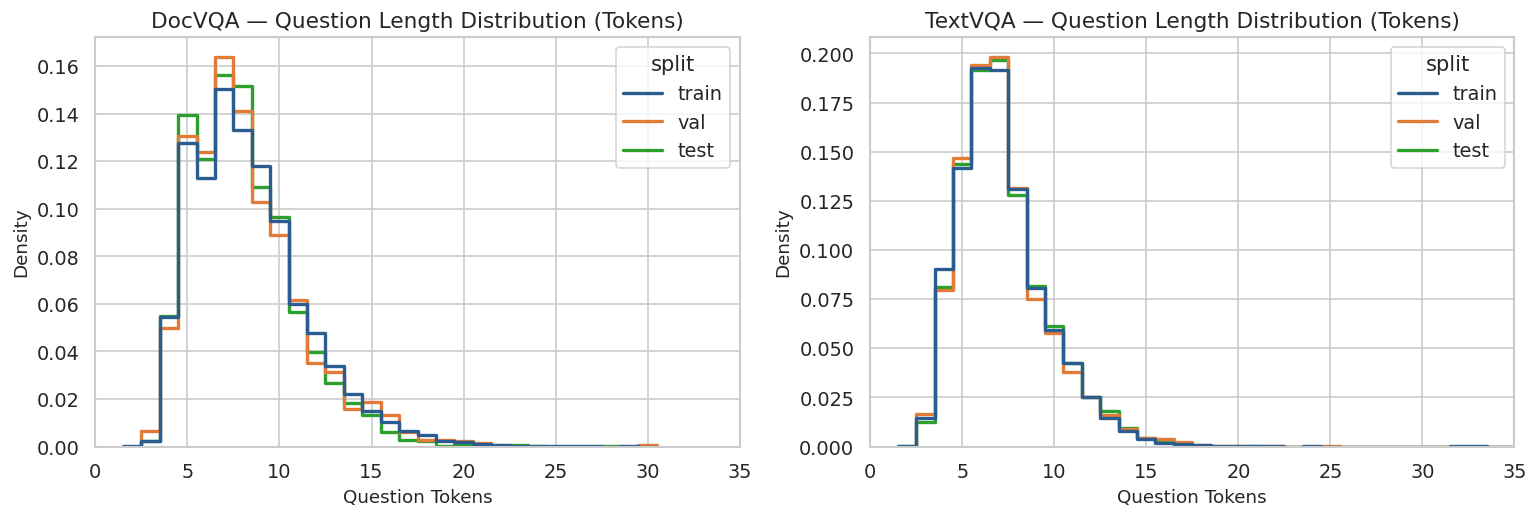

In [ ]:
# ==============================================================================
# 2. PLOT: QUESTION TOKEN LENGTH DISTRIBUTION (Linguistic Invariance)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_queries[df_queries["dataset"] == ds]
    sns.histplot(
        data=sub_df,
        x="question_token_count",
        hue="split",
        palette=SPLIT_PALETTE,
        hue_order=SPLIT_ORDER,
        stat="probability",  # Normalizes all splits to % so train doesn't dwarf val/test
        common_norm=False,
        element="step",  # Draws clean step lines instead of occluding bars
        discrete=True,  # Aligns bins directly to integers (1, 2, 3...)
        fill=False,
        linewidth=2,
        ax=ax,
    )
    ax.set_title(f"{ds} — Question Length Distribution (Tokens)")
    ax.set_xlabel("Question Tokens")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 35)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1237/1752771628.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1237/1752771628.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


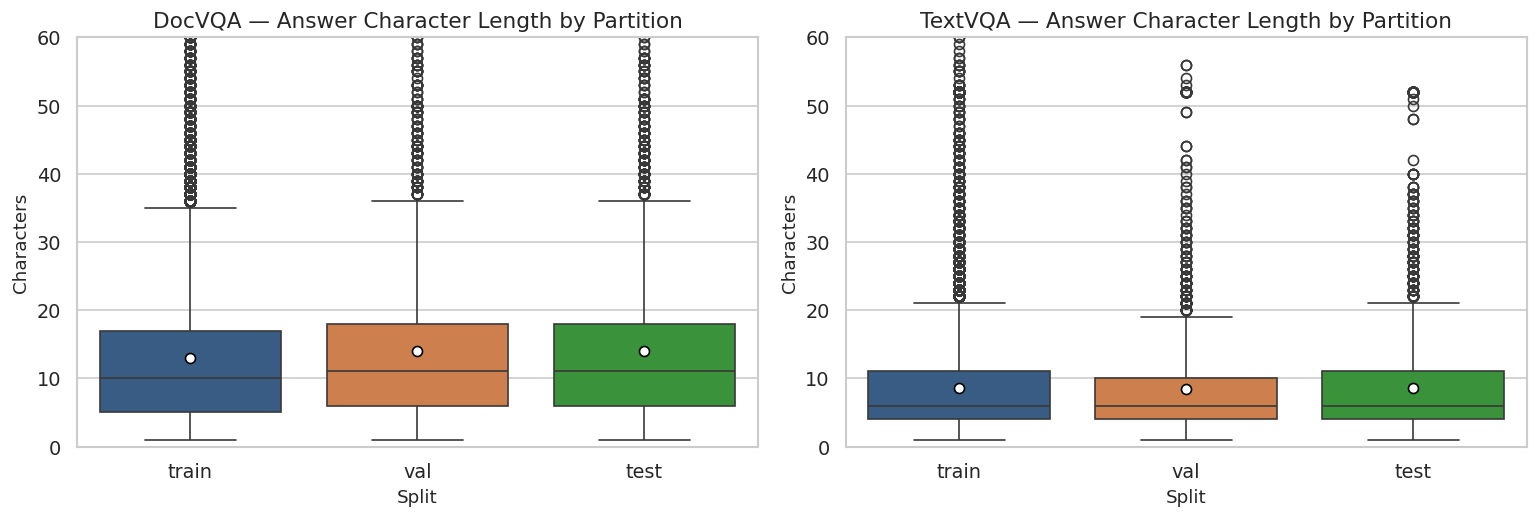

In [ ]:
# ==============================================================================
# 3. PLOT: CANONICAL ANSWER CHARACTER LENGTH (Answer Brevity & Covariate Check)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_queries[df_queries["dataset"] == ds]
    sns.boxplot(
        data=sub_df, x="split", y="canonical_answer_char_len", order=SPLIT_ORDER,
        palette=SPLIT_PALETTE, ax=ax, showmeans=True,
        meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
    )
    ax.set_title(f"{ds} — Answer Character Length by Partition")
    ax.set_xlabel("Split")
    ax.set_ylabel("Characters")
    ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()


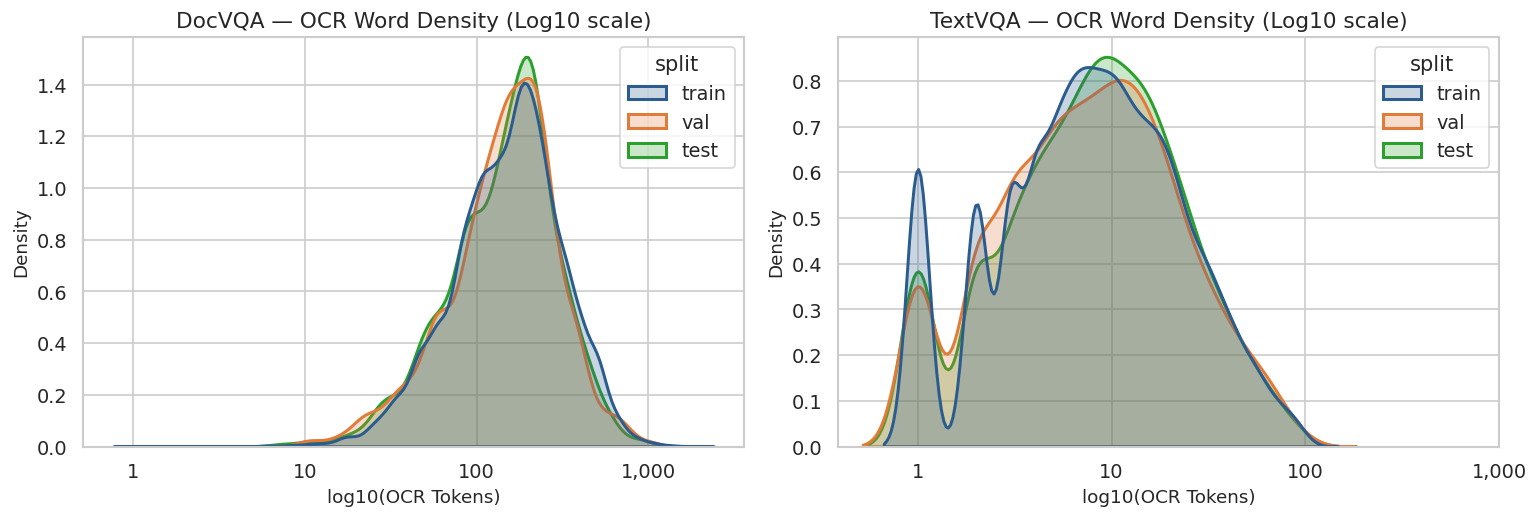

In [96]:
# ==============================================================================
# 4. PLOT: OCR TOKEN DENSITY PER PAGE (Log-Scale Distribution)
# ==============================================================================
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_queries[df_queries["dataset"] == ds].copy()
    sub_df["log10_ocr_tokens"] = np.log10(np.maximum(sub_df["ocr_token_count"], 1))
    
    sns.kdeplot(
        data=sub_df, x="log10_ocr_tokens", hue="split",
        palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER,
        common_norm=False, fill=True, alpha=0.25, linewidth=1.8, ax=ax
    )
    ax.set_title(f"{ds} — OCR Word Density (Log10 scale)")
    ax.set_xlabel("log10(OCR Tokens)")
    ax.set_ylabel("Density")
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xticklabels(["1", "10", "100", "1,000"])

plt.tight_layout()
plt.show()


/tmp/ipykernel_1237/2994105108.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1237/2994105108.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


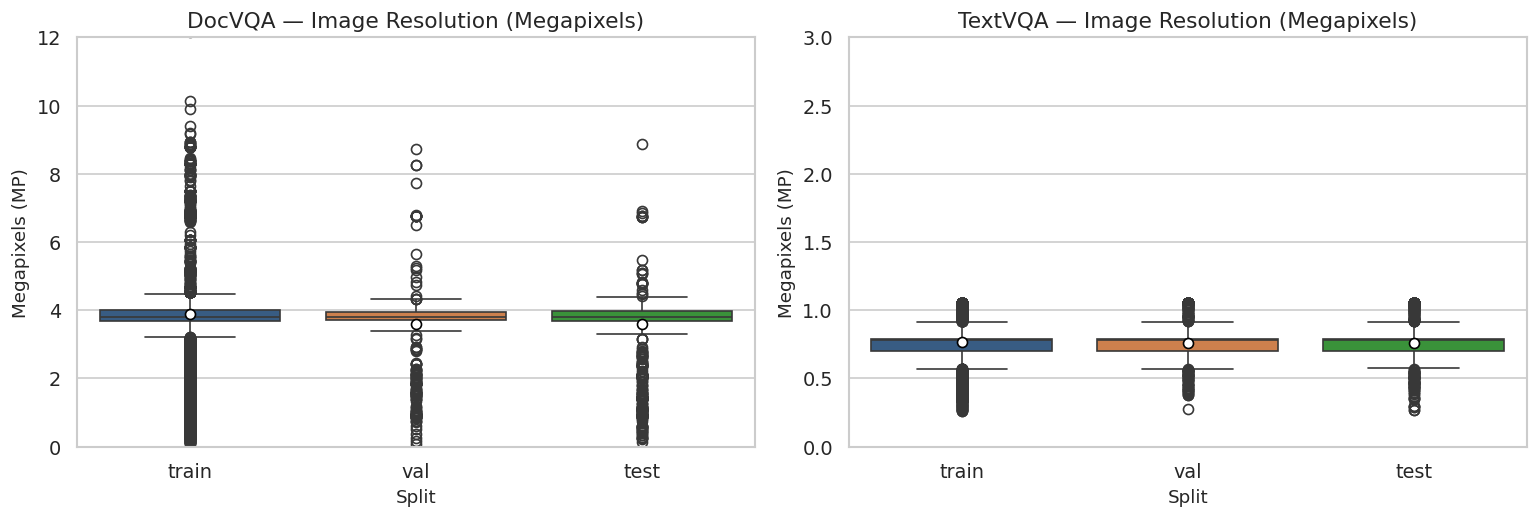

In [ ]:
# ==============================================================================
# 5. PLOT: IMAGE RESOLUTION IN MEGAPIXELS (Physical Geometry Parity)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_images[df_images["dataset"] == ds]
    sns.boxplot(
        data=sub_df, x="split", y="image_megapixels", order=SPLIT_ORDER,
        palette=SPLIT_PALETTE, ax=ax, showmeans=True,
        meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
    )
    ax.set_title(f"{ds} — Image Resolution (Megapixels)")
    ax.set_xlabel("Split")
    ax.set_ylabel("Megapixels (MP)")
    if ds == "DocVQA":
        ax.set_ylim(0, 12)
    else:
        ax.set_ylim(0, 3)

plt.tight_layout()
plt.show()


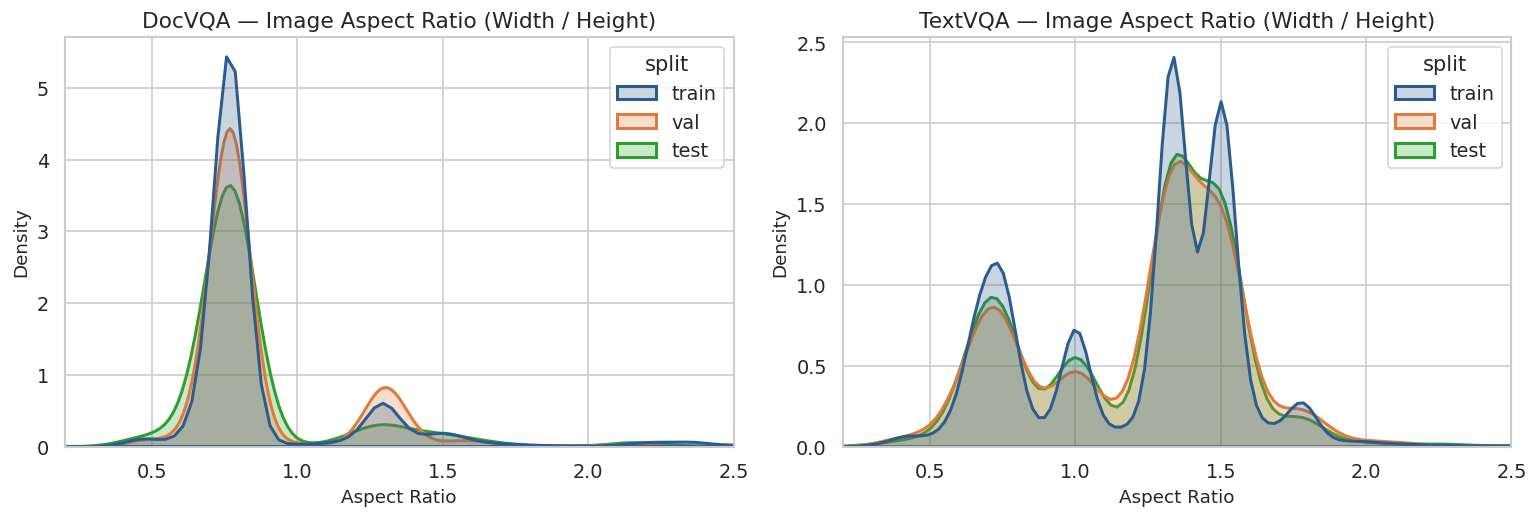

In [ ]:
# ==============================================================================
# 6. PLOT: IMAGE ASPECT RATIO (Portrait vs Landscape Alignment)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_images[df_images["dataset"] == ds]
    sns.kdeplot(
        data=sub_df, x="image_aspect_ratio", hue="split",
        palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER,
        common_norm=False, fill=True, alpha=0.25, linewidth=1.8, ax=ax
    )
    ax.set_title(f"{ds} — Image Aspect Ratio (Width / Height)")
    ax.set_xlabel("Aspect Ratio")
    ax.set_ylabel("Density")
    ax.set_xlim(0.2, 2.5)

plt.tight_layout()
plt.show()


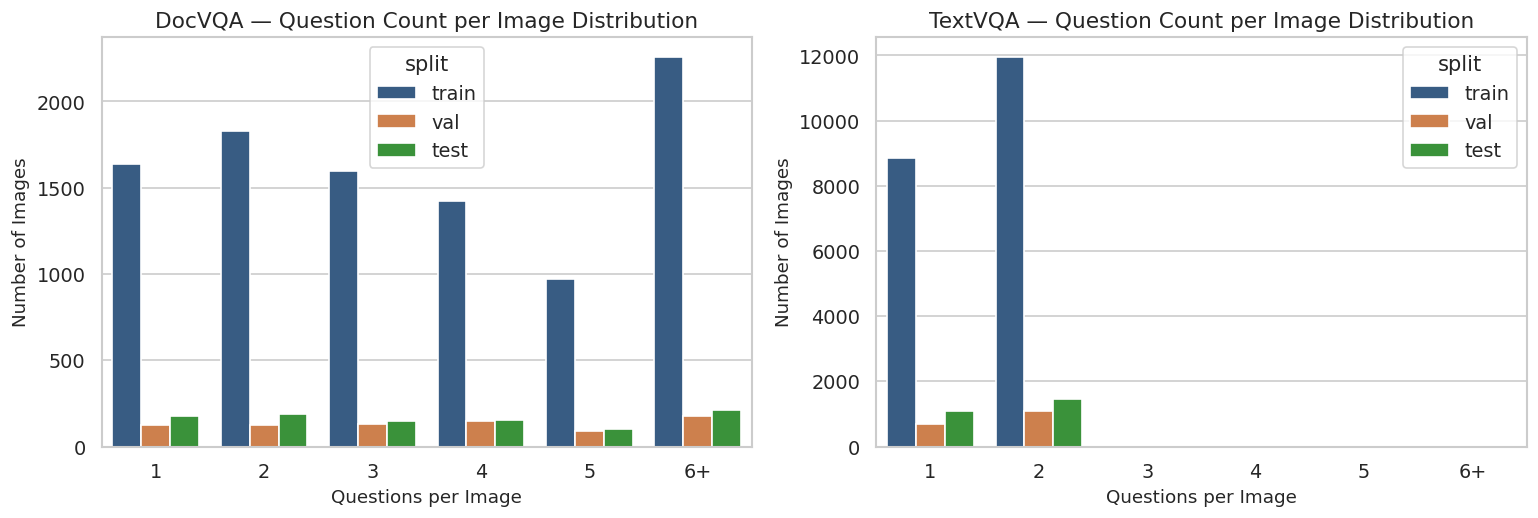

In [ ]:
# ==============================================================================
# 7. PLOT: QUESTION CONCENTRATION PER UNIQUE IMAGE (Query Density per Image)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_images[df_images["dataset"] == ds].copy()
    sub_df["q_bins"] = sub_df["questions_per_image"].apply(lambda x: str(x) if x < 6 else "6+")
    bin_order = ["1", "2", "3", "4", "5", "6+"]
    
    sns.countplot(
        data=sub_df, x="q_bins", hue="split", order=bin_order,
        palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER, ax=ax
    )
    ax.set_title(f"{ds} — Question Count per Image Distribution")
    ax.set_xlabel("Questions per Image")
    ax.set_ylabel("Number of Images")

plt.tight_layout()
plt.show()


/tmp/ipykernel_1237/633619223.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


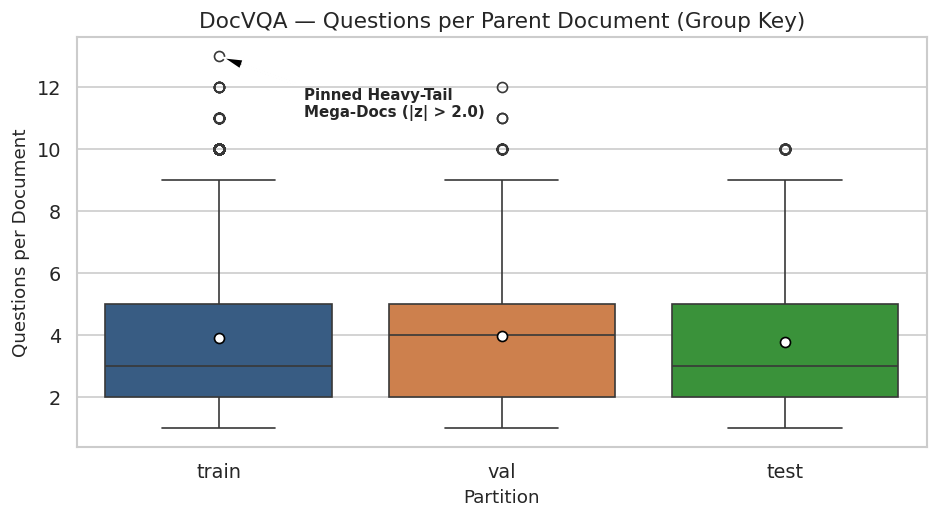

In [ ]:
# ==============================================================================
# 8. PLOT: QUESTIONS PER PARENT DOCUMENT (DocVQA Mega-Document Isolation)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5))

docvqa_docs = df_docs[df_docs["dataset"] == "DocVQA"]
sns.boxplot(
    data=docvqa_docs, x="split", y="questions_per_document", order=SPLIT_ORDER,
    palette=SPLIT_PALETTE, ax=ax, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
)
ax.set_title("DocVQA — Questions per Parent Document (Group Key)")
ax.set_xlabel("Partition")
ax.set_ylabel("Questions per Document")

max_tr = docvqa_docs[docvqa_docs["split"] == "train"]["questions_per_document"].max()
ax.annotate(
    "Pinned Heavy-Tail\nMega-Docs (|z| > 2.0)",
    xy=(0, max_tr),
    xytext=(0.3, max_tr * 0.85),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontsize=9, fontweight="bold"
)

plt.tight_layout()
plt.show()


In [110]:
df_docs

,parent_doc_id,questions_per_document,pages_per_document,total_doc_ocr_tokens,avg_page_ocr_tokens,avg_question_tokens_per_doc,avg_page_megapixels,dataset,split
0,3edcd0df0df6032c,2,1,2,1.000000,11.000000,0.589824,TextVQA,train
1,00d457b6a730342a,1,1,5,5.000000,9.000000,0.786432,TextVQA,train
2,689957a1e09efee8,1,1,19,19.000000,5.000000,0.786432,TextVQA,train
3,b8cce963b2aed20e,1,1,3,3.000000,7.000000,1.048576,TextVQA,train
4,01f45db1ff7610c5,2,1,2,1.000000,8.000000,0.726016,TextVQA,train
...,...,...,...,...,...,...,...,...,...
30801,zpcg0227,5,1,945,189.000000,5.800000,4.070088,DocVQA,test
30802,srpc0227,2,1,108,54.000000,8.500000,4.085580,DocVQA,test
30803,mjff0065,3,1,1146,382.000000,7.666667,3.798540,DocVQA,test
30804,trfm0227,1,1,84,84.000000,6.000000,3.564870,DocVQA,test


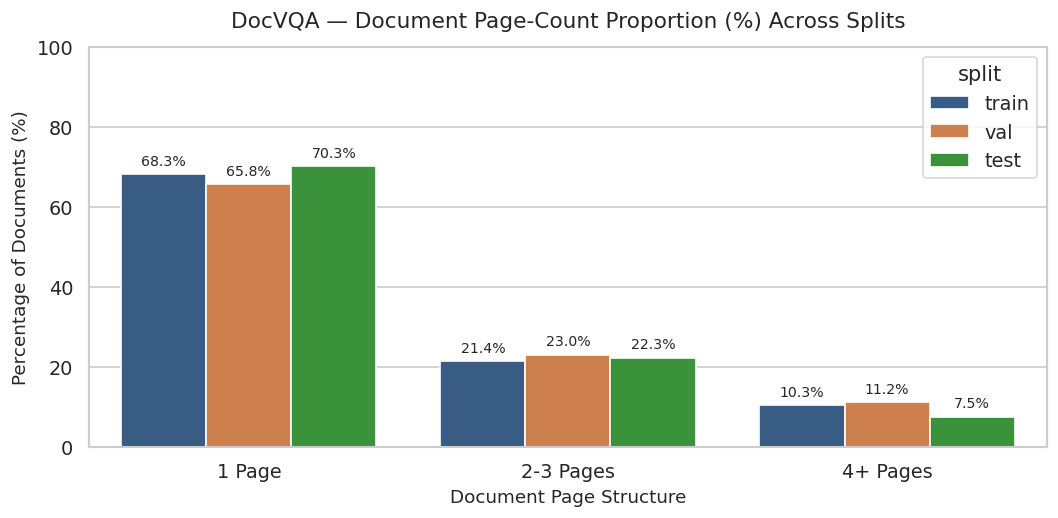

In [107]:
# ==============================================================================
# 9. PLOT: MULTI-PAGE DOCUMENT PROPORTION IN DOCVQA (Single vs Multi-Page)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 4.5))

docvqa_pages = df_docs[df_docs["dataset"] == "DocVQA"].copy()
docvqa_pages["page_bins"] = docvqa_pages["pages_per_document"].apply(
    lambda x: "1 Page" if x == 1 else ("2-3 Pages" if x <= 3 else "4+ Pages")
)
page_order = ["1 Page", "2-3 Pages", "4+ Pages"]

# Modern, clean percentage calculation without groupby.apply() index collision
prop_df = (
    docvqa_pages.groupby(["split", "page_bins"], as_index=False)
    .size()
    .assign(
        percentage=lambda d: 100
        * d["size"]
        / d.groupby("split")["size"].transform("sum")
    )
)

sns.barplot(
    data=prop_df,
    x="page_bins",
    y="percentage",
    hue="split",
    order=page_order,
    palette=SPLIT_PALETTE,
    hue_order=SPLIT_ORDER,
    ax=ax,
)

ax.set_title(
    "DocVQA — Document Page-Count Proportion (%) Across Splits",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Document Page Structure", fontsize=11)
ax.set_ylabel("Percentage of Documents (%)", fontsize=11)
ax.set_ylim(0, 100)

# Add exact percentage labels on top of each bar
for p in ax.patches:
  h = p.get_height()
  if h > 0:
    ax.annotate(
        f"{h:.1f}%",
        (p.get_x() + p.get_width() / 2.0, h + 1.5),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

plt.tight_layout()
plt.show()

## LINGUISTIC & SEMANTIC TAXONOMY (QUESTIONS & ANSWERS)

Investigating interrogative intent (WH-questions and Boolean), semantic answer nature, crowdsourced annotator consensus, and the 4-tier fuzzy-aware extractive OCR grounding spectrum.


In [159]:
# ==============================================================================
# 1. FILTERING CORE QUESTION, ANSWER & TOKEN COLUMNS (PREVIEW)
# ==============================================================================
core_cols = [
    "sample_id", "dataset", "split", "question", "question_tokens",
    "canonical_answer", "answers", "ocr_token_count"
]
df_qa_preview = df_queries[[c for c in core_cols if c in df_queries.columns]]

print("=" * 80)
print("DOCVQA: TEXTUAL & TOKEN FIELD PREVIEW (FIRST 5 ROWS)")
print("=" * 80)
display(df_qa_preview[df_qa_preview["dataset"] == "DocVQA"].head(5))

print("\n" + "=" * 80)
print("TEXTVQA: TEXTUAL & TOKEN FIELD PREVIEW (FIRST 5 ROWS)")
print("=" * 80)
display(df_qa_preview[df_qa_preview["dataset"] == "TextVQA"].head(5))


DOCVQA: TEXTUAL & TOKEN FIELD PREVIEW (FIRST 5 ROWS)


,sample_id,dataset,split,question,question_tokens,canonical_answer,answers,ocr_token_count
39602,docvqa_339,DocVQA,train,Which corporation's letterhead is this?,"[which, corporation's, letterhead, is, this?]",Brown & Williamson Tobacco Corporation,[Brown & Williamson Tobacco Corporation],323
39603,docvqa_340,DocVQA,train,Who is in cc in this letter?,"[who, is, in, cc, in, this, letter?]",T.F. Riehl,[T.F. Riehl],323
39604,docvqa_341,DocVQA,train,what is the subject of this letter?,"[what, is, the, subject, of, this, letter?]",Review of existing Brainstorming Ideas/483,[Review of existing Brainstorming Ideas/483],323
39605,docvqa_343,DocVQA,train,"What is the number at the bottom of the page, ...","[what, is, the, number, at, the, bottom, of, t...",499150498,[499150498],323
39606,docvqa_399,DocVQA,train,what is the date in the letter,"[what, is, the, date, in, the, letter]","June 11, 1990","[June 11, 1990, June 11,1990]",350



TEXTVQA: TEXTUAL & TOKEN FIELD PREVIEW (FIRST 5 ROWS)


,sample_id,dataset,split,question,question_tokens,canonical_answer,answers,ocr_token_count
0,textvqa_1,TextVQA,train,what type of plane is this?,"[what, type, of, plane, is, this]",lape,"[lape, cargo, ec-agg, lape, lape, lape, lape, ...",5
1,textvqa_2,TextVQA,train,what are the letters on the tail section of th...,"[what, are, the, letters, on, the, tail, secti...",ec,"[ec agg, ec-agg, ec, ec-agg, ec, ec, ec, ec, e...",5
2,textvqa_3,TextVQA,train,who is this copyrighted by?,"[who, is, this, copyrighted, by]",simon clancy,"[simon clancy, simon ciancy, simon clancy, sim...",7
3,textvqa_4,TextVQA,train,what brand is on the plane?,"[what, brand, is, on, the, plane]",virgin,"[virgin is the brand on the plane., virgin mob...",7
4,textvqa_5,TextVQA,train,what year is shown in the photo?,"[what, year, is, shown, in, the, photo]",2011,"[2011, 2011, 2011, 2011, 2011, 2011, 2011, 201...",12


In [177]:
# ==============================================================================
# 2. ENRICH WITH QA TAXONOMY, 4-TIER FUZZY OCR GROUNDING & CONSENSUS
# ==============================================================================
from collections import Counter
import difflib
import re
import numpy as np
import pandas as pd

def classify_qa_taxonomy(df):
    df_tax = df.copy()
    
    # --- 1. Question Intent Classification (WH-Questions & Boolean) ---
    def get_q_type(q):
        if not isinstance(q, str):
            return "Other / Non-WH"
        q_clean = q.strip()
        if re.search(r"(?i)^(what\b)", q_clean):
            return "What"
        if re.search(r"(?i)^(where\b)", q_clean):
            return "Where"
        if re.search(r"(?i)^(when\b|what date|what year)", q_clean):
            return "When / Date"
        if re.search(r"(?i)^(who|whose|whom)\b", q_clean):
            return "Who / Entity"
        if re.search(r"(?i)^(which\b)", q_clean):
            return "Which"
        if re.search(r"(?i)^(why\b)", q_clean):
            return "Why"
        if re.search(r"(?i)^(how many|how much|what amount|what is the total|total)\b", q_clean):
            return "How / Quantity"
        if re.search(r"(?i)^(how\b)", q_clean):
            return "How (Method)"
        if re.search(r"(?i)^(is|are|was|were|do|does|did|can|could|has|have|had)\b", q_clean):
            return "Boolean (Yes/No)"
        return "Other / Imperative"
        
    df_tax["question_type"] = df_tax["question"].apply(get_q_type)
    
    # --- 2. Answer Content Classification (Space-Delimited Words) ---
    def get_a_type(ans):
        if not isinstance(ans, str) or not ans.strip():
            return "Unknown / Empty"
        ans_clean = ans.strip()
        words = ans_clean.split()
        
        # Check Boolean
        if re.match(r"(?i)^(yes|no|true|false)$", ans_clean):
            return "Boolean"
        # Check Date / Temporal
        if re.search(r"(?i)\b(\d{1,2}/\d{1,2}/\d{2,4}|jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)\b", ans_clean):
            return "Date / Time"
        # Check Numeric / Currency / Percentage
        if re.match(r"^[\$€£¥]?\s*[-+]?[\d,]+(\.\d+)?\s*[%]?$", ans_clean):
            return "Numeric / Quantity"
        # Space-delimited length classification: <=2 words short text, >=3 words long phrase
        if len(words) <= 2:
            return "Short Text (<=2 words)"
        else:
            return "Long Phrase (>=3 words)"
            
    df_tax["answer_content_type"] = df_tax["canonical_answer"].apply(get_a_type)
    
    # --- 3. Crowdsourced Consensus & Agreement Rate ---
    def get_consensus(answers_list):
        if not isinstance(answers_list, (list, np.ndarray)) or len(answers_list) == 0:
            return 1.0, 1
        cleaned = [str(a).lower().strip() for a in answers_list if str(a).strip()]
        if not cleaned:
            return 1.0, 1
        counts = Counter(cleaned)
        most_common_cnt = counts.most_common(1)[0][1]
        return (most_common_cnt / len(cleaned)), len(counts)
        
    consensus_tuples = df_tax["answers"].apply(get_consensus)
    df_tax["consensus_rate"] = [t[0] for t in consensus_tuples]
    df_tax["unique_answers_count"] = [t[1] for t in consensus_tuples]
    
    # --- 4. 4-Tier Fuzzy-Aware Extractive vs Abstractive OCR Grounding Spectrum ---
    # S = Tokens(a) intersect Tokens_OCR(q) (with Levenshtein OCR-noise tolerance)
    # Tier 1: OCR Miss (Empty OCR)         -> len(ocr_tokens) == 0
    # Tier 2: Fully Extractive (100% OCR)  -> all answer tokens match or substring match
    # Tier 3: Partially Extractive (Hybrid)-> 0 < matched tokens < total answer tokens
    # Tier 4: Abstractive / Reasoning      -> 0 matched tokens (when OCR is present)
    def is_token_grounded(word, ocr_set):
        if word in ocr_set:
            return True
        w_len = len(word)
        # Require exact match for short words (<= 3 chars) to avoid false positives (e.g. no vs to)
        if w_len <= 3:
            return False
        # For words >= 4 chars, allow 1-character typo/OCR transcription noise
        for t in ocr_set:
            if abs(len(t) - w_len) <= 1:
                if difflib.SequenceMatcher(None, word, t).quick_ratio() >= 0.75:
                    if difflib.SequenceMatcher(None, word, t).ratio() >= 0.75:
                        return True
        return False

    def get_grounding(row):
        ans = str(row["canonical_answer"]).lower().strip()
        ocr_toks = row.get("ocr_tokens")
        
        # Total OCR detection failure
        if not isinstance(ocr_toks, (list, np.ndarray)) or len(ocr_toks) == 0:
            return "OCR Miss (Empty OCR)"
            
        ocr_set = {str(t).lower().strip() for t in ocr_toks if str(t).strip()}
        if not ocr_set:
            return "OCR Miss (Empty OCR)"
            
        ans_tokens = [w for w in ans.split() if w]
        if not ans_tokens:
            return "Abstractive / Reasoning"
            
        # Fast full exact substring match in concatenated OCR text
        ocr_full_str = " ".join(ocr_set)
        if ans in ocr_full_str:
            return "Fully Extractive (100% in OCR)"
            
        # Token-by-token evaluation with typo tolerance
        matched = sum(1 for w in ans_tokens if is_token_grounded(w, ocr_set))
        if matched == len(ans_tokens):
            return "Fully Extractive (100% in OCR)"
        elif matched > 0:
            return "Partially Extractive (Hybrid)"
        else:
            return "Abstractive / Reasoning"
            
    df_tax["ocr_grounding"] = df_tax.apply(get_grounding, axis=1)
    return df_tax

print("Extracting Question & Answer Linguistic Taxonomy with Fuzzy OCR Grounding...")
df_taxonomy = classify_qa_taxonomy(df_queries)

# --- Automated Verification Assertions ---
assert df_taxonomy["question_type"].isnull().sum() == 0, "Nulls found in question_type!"
assert df_taxonomy["answer_content_type"].isnull().sum() == 0, "Nulls found in answer_content_type!"
assert df_taxonomy["ocr_grounding"].isnull().sum() == 0, "Nulls found in ocr_grounding!"
assert df_taxonomy["consensus_rate"].between(0.0, 1.0).all(), "consensus_rate out of [0, 1] bounds!"

valid_grounding = {
    "Fully Extractive (100% in OCR)",
    "Partially Extractive (Hybrid)",
    "Abstractive / Reasoning",
    "OCR Miss (Empty OCR)"
}
assert set(df_taxonomy["ocr_grounding"].unique()).issubset(valid_grounding), "Invalid grounding categories found!"

print(f"✓ Taxonomy extracted and verified for {len(df_taxonomy):,} total queries across both datasets.")


Extracting Question & Answer Linguistic Taxonomy with Fuzzy OCR Grounding...
✓ Taxonomy extracted and verified for 84,414 total queries across both datasets.


In [178]:
# ==============================================================================
# 3. SUMMARY: QUESTION & ANSWER TAXONOMY CROSS-TABULATION
# ==============================================================================
qa_summary = (
    df_taxonomy.groupby(["dataset", "split", "question_type", "answer_content_type"], as_index=False)
    .size()
    .sort_values(by=["dataset", "split", "size"], ascending=[True, True, False])
)

print("Top 10 QA Patterns in DocVQA Train:")
display(qa_summary[(qa_summary["dataset"] == "DocVQA") & (qa_summary["split"] == "train")].head(10))

print("\nTop 10 QA Patterns in TextVQA Train:")
display(qa_summary[(qa_summary["dataset"] == "TextVQA") & (qa_summary["split"] == "train")].head(10))


Top 10 QA Patterns in DocVQA Train:


,dataset,split,question_type,answer_content_type,size
50,DocVQA,train,What,Numeric / Quantity,10317
51,DocVQA,train,What,Short Text (<=2 words),7792
49,DocVQA,train,What,Long Phrase (>=3 words),6768
66,DocVQA,train,Who / Entity,Long Phrase (>=3 words),1904
48,DocVQA,train,What,Date / Time,1433
68,DocVQA,train,Who / Entity,Short Text (<=2 words),1417
46,DocVQA,train,Other / Imperative,Short Text (<=2 words),1390
40,DocVQA,train,How / Quantity,Numeric / Quantity,1311
44,DocVQA,train,Other / Imperative,Long Phrase (>=3 words),1187
64,DocVQA,train,Which,Short Text (<=2 words),784



Top 10 QA Patterns in TextVQA Train:


,dataset,split,question_type,answer_content_type,size
152,TextVQA,train,What,Short Text (<=2 words),18633
151,TextVQA,train,What,Numeric / Quantity,3847
150,TextVQA,train,What,Long Phrase (>=3 words),2987
133,TextVQA,train,Boolean (Yes/No),Boolean,1592
167,TextVQA,train,Who / Entity,Short Text (<=2 words),1422
141,TextVQA,train,How / Quantity,Numeric / Quantity,726
147,TextVQA,train,Other / Imperative,Short Text (<=2 words),628
163,TextVQA,train,Which,Short Text (<=2 words),497
159,TextVQA,train,Where,Short Text (<=2 words),416
143,TextVQA,train,Other / Imperative,Boolean,258


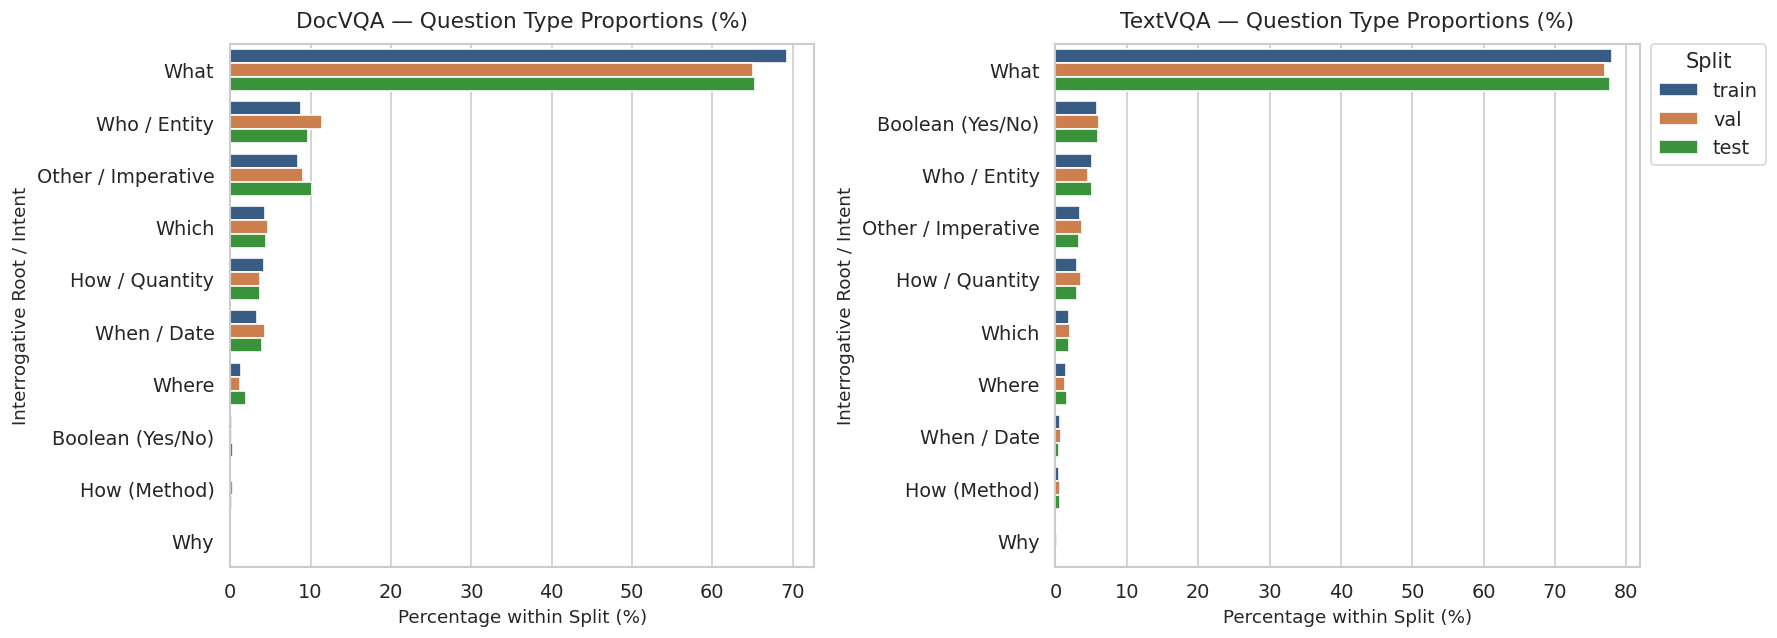

In [179]:
# ==============================================================================
# 4. PLOT: QUESTION INTENT TAXONOMY (WH-Questions & Boolean Proportions)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for idx, (ax, ds) in enumerate(zip(axes, ["DocVQA", "TextVQA"])):
    sub_df = df_taxonomy[df_taxonomy["dataset"] == ds]
    
    prop_df = (
        sub_df.groupby(["split", "question_type"], as_index=False)
        .size()
        .assign(percentage=lambda d: 100 * d["size"] / d.groupby("split")["size"].transform("sum"))
    )
    
    q_order = sub_df["question_type"].value_counts().index.tolist()
    
    sns.barplot(
        data=prop_df, x="percentage", y="question_type", hue="split",
        order=q_order, palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER, ax=ax
    )
    ax.set_title(f"{ds} — Question Type Proportions (%)", fontsize=13, pad=10)
    ax.set_xlabel("Percentage within Split (%)", fontsize=11)
    ax.set_ylabel("Interrogative Root / Intent", fontsize=11)
    
    # Remove legend from the left plot to avoid redundancy
    if idx == 0:
        ax.get_legend().remove()
    else:
        # Shift legend outside to the right of the second plot
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, title="Split")
    
plt.tight_layout()
plt.show()

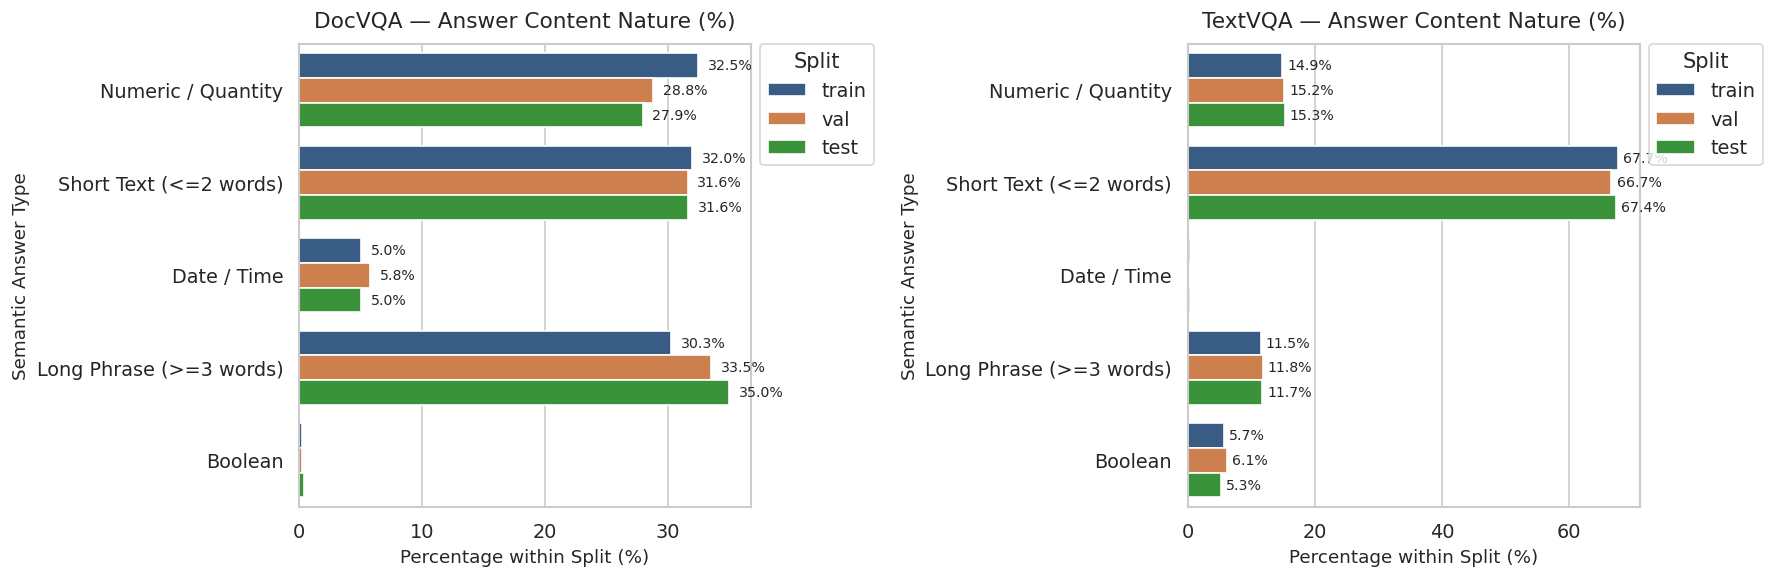

In [180]:
# ==============================================================================
# 5. PLOT: ANSWER SEMANTIC CONTENT NATURE PROPORTIONS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

content_order = [
    "Numeric / Quantity", "Short Text (<=2 words)", "Date / Time",
    "Long Phrase (>=3 words)", "Boolean"
]

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_taxonomy[df_taxonomy["dataset"] == ds]
    
    prop_df = (
        sub_df.groupby(["split", "answer_content_type"], as_index=False)
        .size()
        .assign(percentage=lambda d: 100 * d["size"] / d.groupby("split")["size"].transform("sum"))
    )
    
    sns.barplot(
        data=prop_df, x="percentage", y="answer_content_type", hue="split",
        order=content_order, palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER, ax=ax
    )
    ax.set_title(f"{ds} — Answer Content Nature (%)", fontsize=13, pad=10)
    ax.set_xlabel("Percentage within Split (%)", fontsize=11)
    ax.set_ylabel("Semantic Answer Type", fontsize=11)
    
    for p in ax.patches:
        w = p.get_width()
        if w > 1.5:
            ax.annotate(f"{w:.1f}%", (w + 0.8, p.get_y() + p.get_height()/2.),
                        va="center", fontsize=8.5)
        # Remove legend from the left plot to avoid redundancy
    if idx == 0:
        ax.get_legend().remove()
    else:
        # Shift legend outside to the right of the second plot
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, title="Split")

plt.tight_layout()
plt.show()


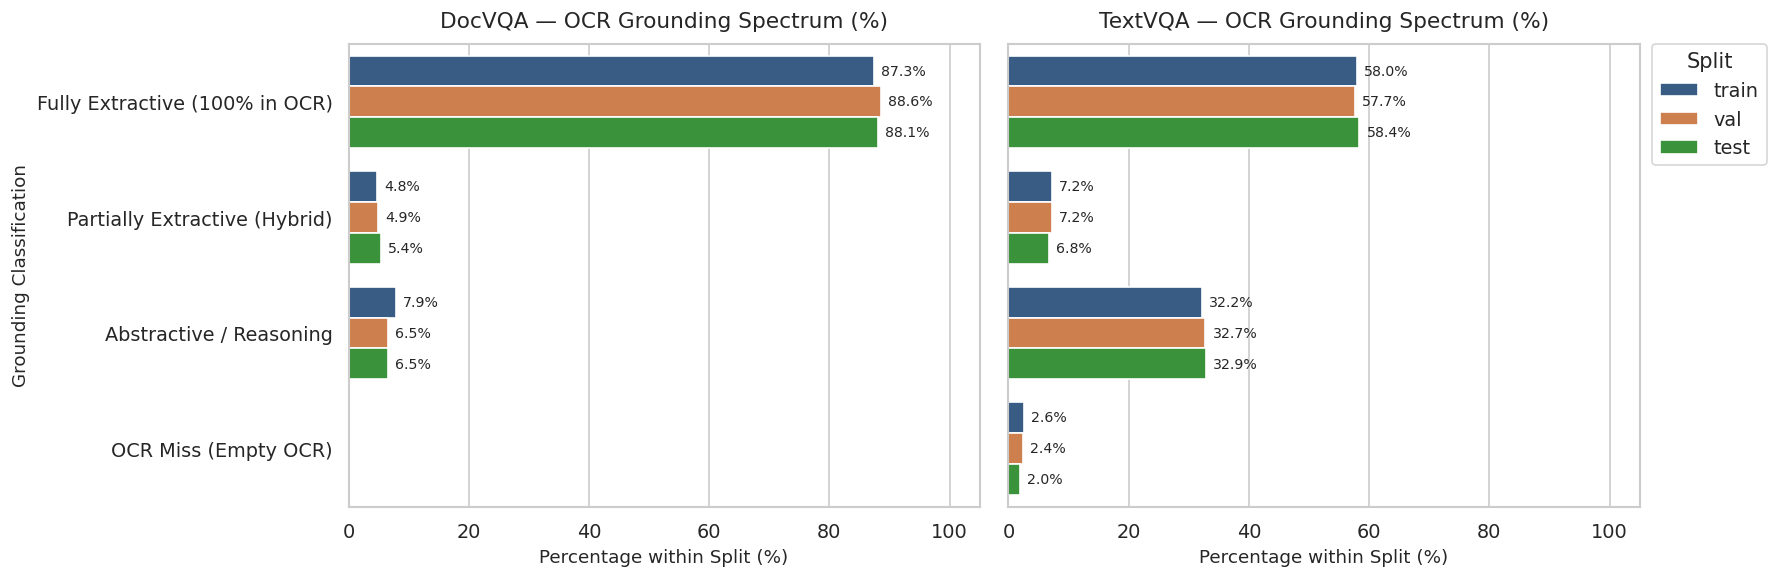

In [181]:
# ==============================================================================
# 6. PLOT: 4-TIER EXTRACTIVE VS ABSTRACTIVE OCR GROUNDING SPECTRUM
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

grounding_order = [
    "Fully Extractive (100% in OCR)",
    "Partially Extractive (Hybrid)",
    "Abstractive / Reasoning",
    "OCR Miss (Empty OCR)"
]

for idx, (ax, ds) in enumerate(zip(axes, ["DocVQA", "TextVQA"])):
    sub_df = df_taxonomy[df_taxonomy["dataset"] == ds]
    
    prop_df = (
        sub_df.groupby(["split", "ocr_grounding"], as_index=False)
        .size()
        .assign(percentage=lambda d: 100 * d["size"] / d.groupby("split")["size"].transform("sum"))
    )
    
    sns.barplot(
        data=prop_df, x="percentage", y="ocr_grounding", hue="split",
        order=grounding_order, palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER, ax=ax
    )
    ax.set_title(f"{ds} — OCR Grounding Spectrum (%)", fontsize=13, pad=10)
    ax.set_xlabel("Percentage within Split (%)", fontsize=11)
    ax.set_ylabel("Grounding Classification" if idx == 0 else "", fontsize=11)
    ax.set_xlim(0, 105)
    
    for p in ax.patches:
        w = p.get_width()
        if w > 0.5:
            ax.annotate(f"{w:.1f}%", (w + 1.2, p.get_y() + p.get_height() / 2.),
                        va="center", fontsize=8.5)

    if idx == 0:
        ax.get_legend().remove()
    else:
        sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, title="Split")

plt.tight_layout()
plt.show()


In [182]:
# View example of extractive, partial vs abstractive/reasoning

# Set display options to ensure full question and token text is visible
pd.set_option("display.max_colwidth", None)

grounding_categories = [
    "Fully Extractive (100% in OCR)",
    "Partially Extractive (Hybrid)",
    "Abstractive / Reasoning",
    "OCR Miss (Empty OCR)"
]

display_cols = [
    "dataset",
    "question",
    "canonical_answer",
    "ocr_grounding",
    "ocr_tokens"
]

# Sample 2 representative rows per category per dataset (train split)
samples = []
for ds in ["DocVQA", "TextVQA"]:
    for g in grounding_categories:
        sub = df_taxonomy[
            (df_taxonomy["dataset"] == ds) &
            (df_taxonomy["split"] == "train") &
            (df_taxonomy["ocr_grounding"] == g)
        ]
        if len(sub) > 0:
            samples.append(sub[display_cols].head(2))

df_examples = pd.concat(samples, ignore_index=True)

# Truncate ocr_tokens preview for clean readability
df_examples["ocr_tokens_preview"] = df_examples["ocr_tokens"].apply(
    lambda x: ", ".join(list(x)[:15]) + ("..." if len(x) > 15 else "") if isinstance(x, (list, tuple)) else str(x)
)

# Display grouped by Dataset & Grounding Category
for (ds, g), group in df_examples.groupby(["dataset", "ocr_grounding"], sort=False):
    print("=" * 100)
    print(f"[{ds}] Grounding Type: {g}")
    print("=" * 100)
    for idx, row in group.iterrows():
        print(f"• Question       : {row['question']}")
        print(f"  Canonical Ans  : '{row['canonical_answer']}'")
        print(f"  OCR Sample     : [{row['ocr_tokens_preview']}]\n")


[DocVQA] Grounding Type: Fully Extractive (100% in OCR)
• Question       : Which corporation's letterhead is this?
  Canonical Ans  : 'Brown & Williamson Tobacco Corporation'
  OCR Sample     : [['B&W' 'BROWN' '&' 'WILLIAMSON' 'TOBACCO' 'CORPORATION' 'RESEARCH' '&'
 'DEVELOPMENT' '.' '.' '.' '.' 'INTERNAL' 'CORRESPONDENCE' 'TO:' 'R.' 'H.'
 'Honeycutt' 'CC:' 'T.F.' 'Riehl' 'FROM:' 'C.' 'J.' 'Cook' 'DATE:' 'May'
 '8.' '1995' 'SUBJECT:' 'Review' 'of' 'Existing' 'Brainstorming'
 'Ideas/483' 'The' 'major' 'function' 'of' 'the' 'Product' 'Innovation'
 'Group' 'is' 'to' 'develop' 'marketable' 'novel' 'products' 'that'
 'would' 'be' 'profitable' 'to' 'manufacture' 'and' 'sell.' 'Novel' 'is'
 'defined' 'as:' 'of' 'a' 'new' 'kind,' 'or' 'different' 'from' 'anything'
 'seen' 'or' 'known' 'before.' 'Innovation' 'is' 'defined' 'as:'
 'something' 'new' 'or' 'different' 'introduced;' 'act' 'of' 'innovating;'
 'introduction' 'of' 'new' 'things' 'or' 'methods.' 'The' 'products' 'may'
 'ncorporate' 'the

In [194]:
abstract_reasoning = df_taxonomy.query("ocr_grounding == 'Abstractive / Reasoning' and question_type == 'Other / Imperative'")

In [195]:
abstract_reasoning.columns

Index(['sample_id', 'domain_type', 'question_id', 'question',
       'question_tokens', 'image_id', 'image_width', 'image_height', 'answers',
       'canonical_answer', 'ocr_tokens', 'ocr_boxes', 'metadata',
       'original_split', 'ocr_token_count', 'question_token_count',
       'answers_count', 'question_char_len', 'canonical_answer_char_len',
       'image_megapixels', 'image_aspect_ratio', 'dataset', 'split',
       'question_type', 'answer_content_type', 'consensus_rate',
       'unique_answers_count', 'ocr_grounding'],
      dtype='object')

In [202]:
# 1. Select relevant Question & Answer focal columns
qa_cols = [
    'sample_id',
    'domain_type',
    "dataset",
    "split",
    "question",
    "question_type",
    "question_token_count",
    "canonical_answer",
    "answers",
    "answer_content_type",
    "consensus_rate",
    "ocr_grounding",
    "ocr_tokens",  # included to inspect why it had zero match
]

# 2. Filter rows with "Abstractive / Reasoning"
df_abstract = df_taxonomy.loc[
    df_taxonomy["ocr_grounding"] == "Abstractive / Reasoning",
    qa_cols
]

# Preview the first 10 rows
display(df_abstract.head(10))

,sample_id,domain_type,dataset,split,question,question_type,question_token_count,canonical_answer,answers,answer_content_type,consensus_rate,ocr_grounding,ocr_tokens
10,textvqa_11,scene_text,TextVQA,train,what airline is this plane for?,What,6,air france,"[airfrance, air france, airfrance, air france, airfrance, airfrance, spanish, air france, air france, air france]",Short Text (<=2 words),0.5,Abstractive / Reasoning,"[AIRFRANCE, CCM, IRFRANCE]"
15,textvqa_17,scene_text,TextVQA,train,what is the last number of the plane?,What,8,3,"[3, 3, 3, traktor, 3, 3, 3, 3, 3, 3]",Numeric / Quantity,0.9,Abstractive / Reasoning,[MEONaN]
18,textvqa_20,scene_text,TextVQA,train,what is the plane number?,What,5,728tfw,"[728, 728tfw, 81, 81728, 728tfw, unanswerable, af91728tfw, 728tfw, 8, wp]",Short Text (<=2 words),0.3,Abstractive / Reasoning,"[WP, AF7281FW]"
21,textvqa_23,scene_text,TextVQA,train,what two numbers can be seen on the white post on the right?,What,13,"25, 50","[23, 25, 25 50, unanswerable, 25, 50 , 25 and 50, 25, 50, 25, 50, 23 50, 25-50]",Short Text (<=2 words),0.3,Abstractive / Reasoning,"[POLITIH, STTY, Brill]"
22,textvqa_24,scene_text,TextVQA,train,what letters are on the craft?,What,6,f-pdhv,"[f-pdhv, f-pdhv, f-pdhv, f-pdhv, f-pdhv, fpdhv, f-pdhv, f-pdhv, f-pdhv, f-pdhv]",Short Text (<=2 words),0.9,Abstractive / Reasoning,"[E.PDHV, neeng.com]"
23,textvqa_25,scene_text,TextVQA,train,what website is labeled on the plane?,What,7,www.verheesengineering.com,"[fpdhv, www.verheesengineering.com, unanswerable, verhesengineering.com, unanswerable, verheesenginering.com, www.verheesengineering.com, www.verhwwsengineering.com, 2, www.verheesengineering.com]",Short Text (<=2 words),0.3,Abstractive / Reasoning,"[E.PDHV, neeng.com]"
29,textvqa_31,scene_text,TextVQA,train,what word does one of the hot balloons feature?,What,9,when,"[when, when, yamaha, when, when, when pigs fly, bobby j's, when, when, when apes fly]",Short Text (<=2 words),0.6,Abstractive / Reasoning,"[V, O, BbyJs, bLY, Is, nort]"
30,textvqa_32,scene_text,TextVQA,train,where is the plane going?,Where,5,unanswerable,"[south african, worth, unanswerable, unanswerable, unanswerable, unanswerable, south africa, south africa, south africa, answering does not require reading text in the image]",Short Text (<=2 words),0.4,Abstractive / Reasoning,"[AFRICAN, ...●●●●*, **, ..SOUTH, ********"", virginalanic, ignaian]"
32,textvqa_34,scene_text,TextVQA,train,what does the white sign say?,What,6,unanswerable,"[a380, airbus a380, unanswerable, unanswerable, unanswerable, airbus a380, airbus, airbus, unanswerable, airbus]",Short Text (<=2 words),0.4,Abstractive / Reasoning,"[.S, NLES, IRBU, BL, US, .....,, A3N.., Gree, A380, Mu30]"
35,textvqa_37,scene_text,TextVQA,train,is there any other text on the plane?,Boolean (Yes/No),8,yes,"[yes, yes, 41, yes, luk, 41, yes, yes, yes, 41, yes]",Boolean,0.6,Abstractive / Reasoning,"[41, SVA, 00-LUK, •, 41]"


/tmp/ipykernel_1237/3826588874.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1237/3826588874.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


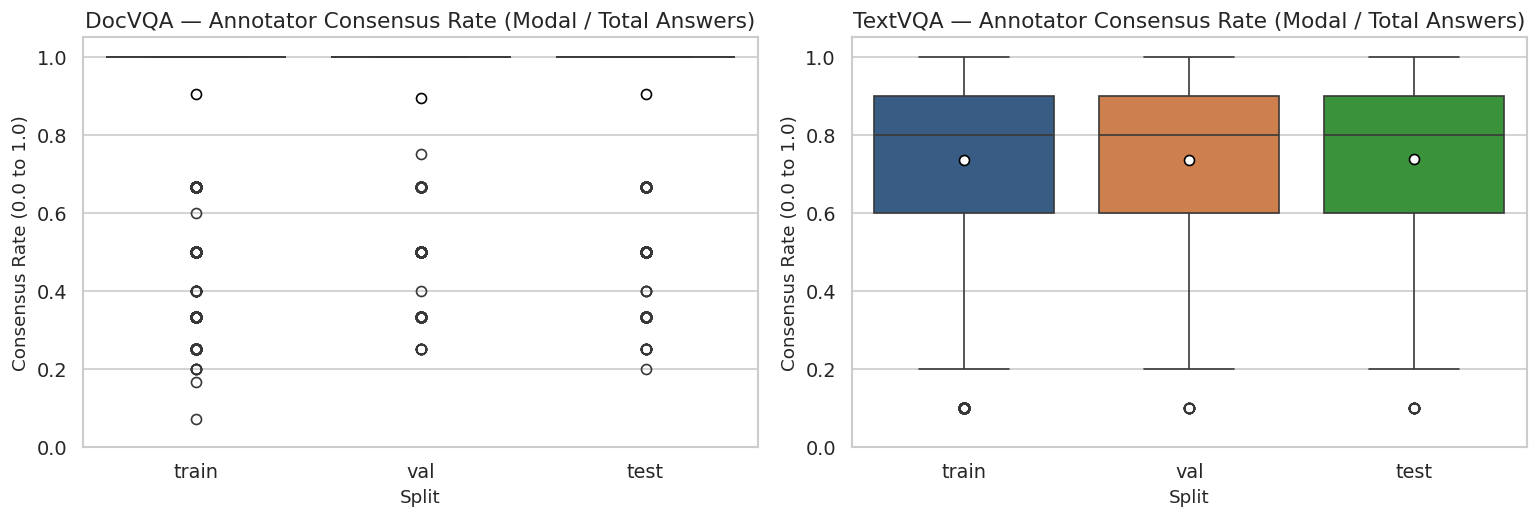

In [172]:
# ==============================================================================
# 7. PLOT: CROWDSOURCED CONSENSUS & ANNOTATOR AGREEMENT RATE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_taxonomy[df_taxonomy["dataset"] == ds]
    sns.boxplot(
        data=sub_df, x="split", y="consensus_rate", order=SPLIT_ORDER,
        palette=SPLIT_PALETTE, ax=ax, showmeans=True,
        meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
    )
    ax.set_title(f"{ds} — Annotator Consensus Rate (Modal / Total Answers)")
    ax.set_xlabel("Split")
    ax.set_ylabel("Consensus Rate (0.0 to 1.0)")
    ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()


In [174]:
# Check exact consensus distribution in DocVQA
doc_consensus = df_taxonomy[df_taxonomy["dataset"] == "DocVQA"]["consensus_rate"]
print(f"DocVQA questions with 100% unanimous consensus: {(doc_consensus == 1.0).mean() * 100:.2f}%")
print(f"DocVQA questions with annotator disagreement (<1.0): {(doc_consensus < 1.0).mean() * 100:.2f}%")

DocVQA questions with 100% unanimous consensus: 81.03%
DocVQA questions with annotator disagreement (<1.0): 18.97%


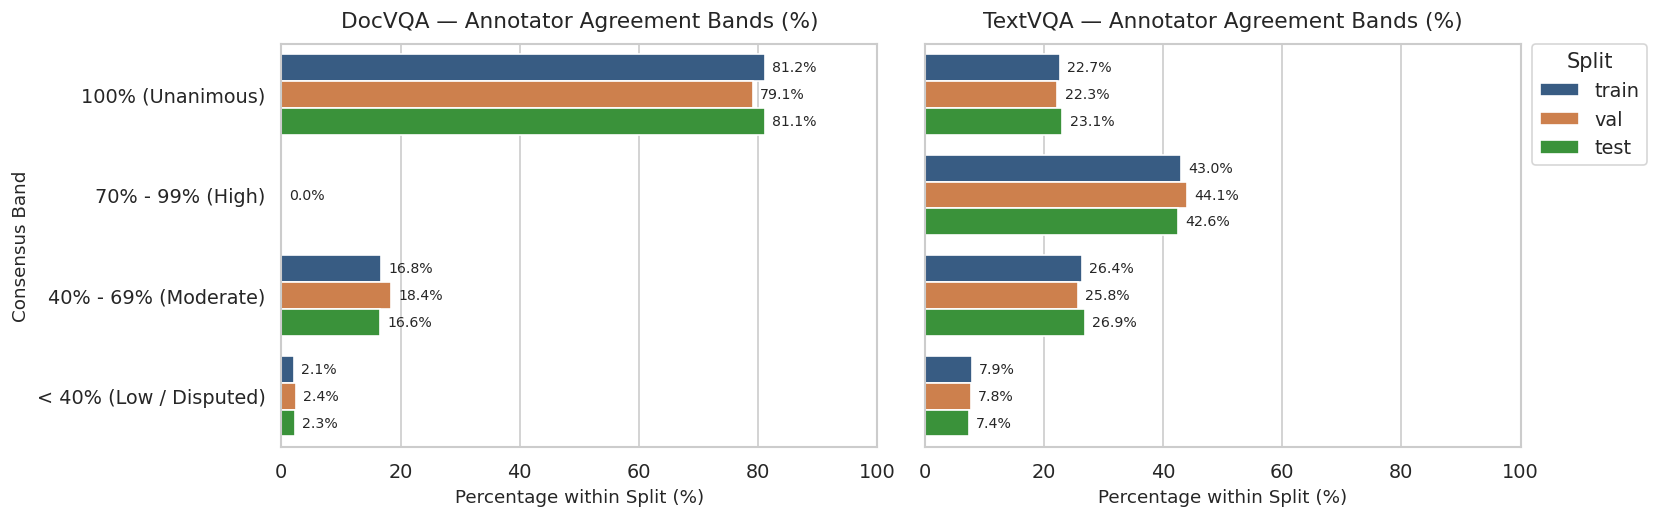

In [175]:
# ==============================================================================
# REPLACEMENT: BINNED ANNOTATOR CONSENSUS PROPORTIONS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

# Define consensus bands
def get_consensus_band(r):
    if r == 1.0:
        return "100% (Unanimous)"
    elif r >= 0.7:
        return "70% - 99% (High)"
    elif r >= 0.4:
        return "40% - 69% (Moderate)"
    else:
        return "< 40% (Low / Disputed)"

df_taxonomy["consensus_band"] = df_taxonomy["consensus_rate"].apply(get_consensus_band)
band_order = ["100% (Unanimous)", "70% - 99% (High)", "40% - 69% (Moderate)", "< 40% (Low / Disputed)"]

for ax, ds in zip(axes, ["DocVQA", "TextVQA"]):
    sub_df = df_taxonomy[df_taxonomy["dataset"] == ds]
    
    prop_df = (
        sub_df.groupby(["split", "consensus_band"], as_index=False)
        .size()
        .assign(percentage=lambda d: 100 * d["size"] / d.groupby("split")["size"].transform("sum"))
    )
    
    sns.barplot(
        data=prop_df, x="percentage", y="consensus_band", hue="split",
        order=band_order, palette=SPLIT_PALETTE, hue_order=SPLIT_ORDER, ax=ax
    )
    ax.set_title(f"{ds} — Annotator Agreement Bands (%)", fontsize=13, pad=10)
    ax.set_xlabel("Percentage within Split (%)", fontsize=11)
    ax.set_ylabel("Consensus Band" if ds == "DocVQA" else "", fontsize=11)
    ax.set_xlim(0, 100)
    
    # Add data labels
    for p in ax.patches:
        w = p.get_width()
        if w > 0:
            ax.annotate(f"{w:.1f}%", (w + 1.2, p.get_y() + p.get_height() / 2.),
                        ha="left", va="center", fontsize=8.5)

axes[0].get_legend().remove()
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, title="Split")

plt.tight_layout()
plt.show()

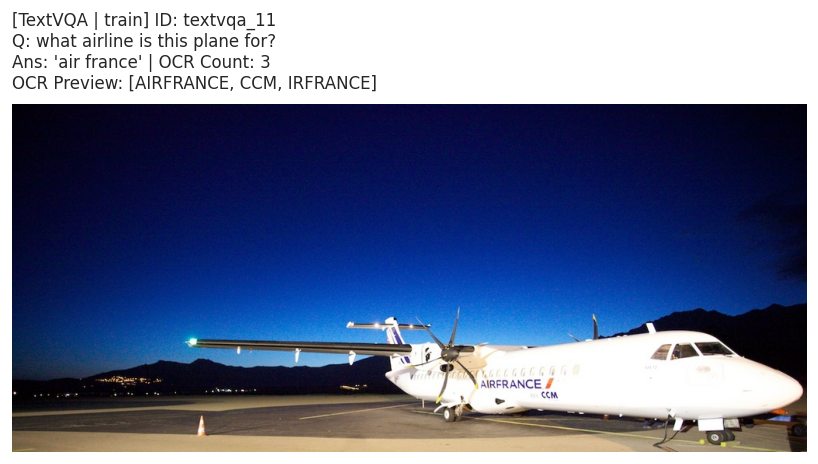

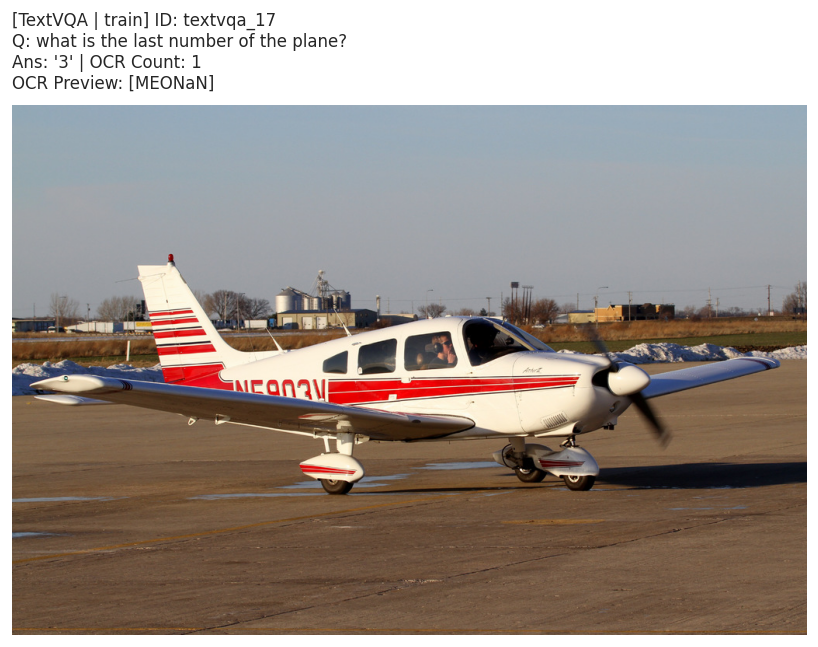

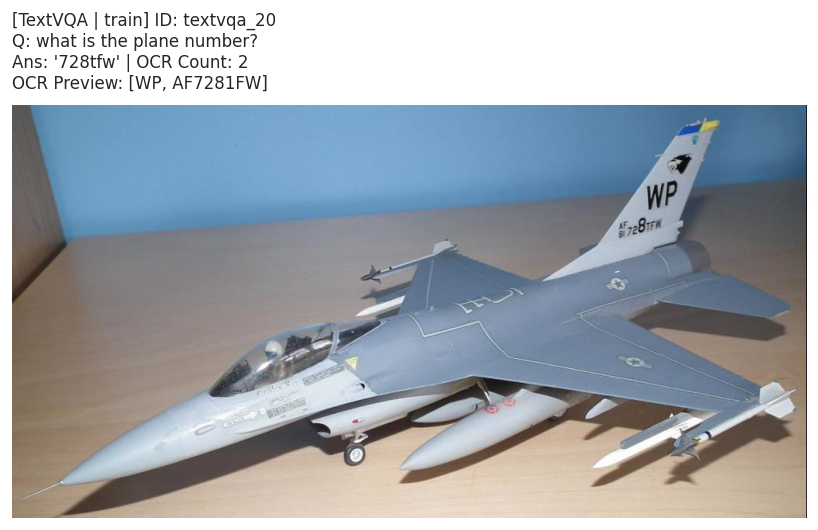

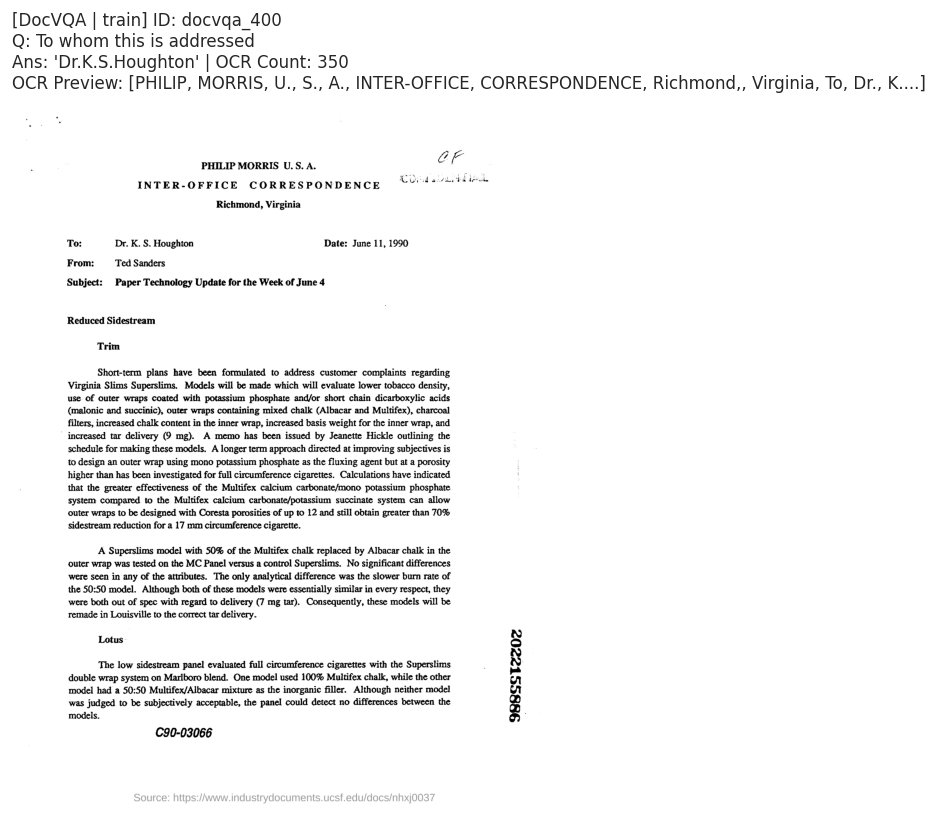

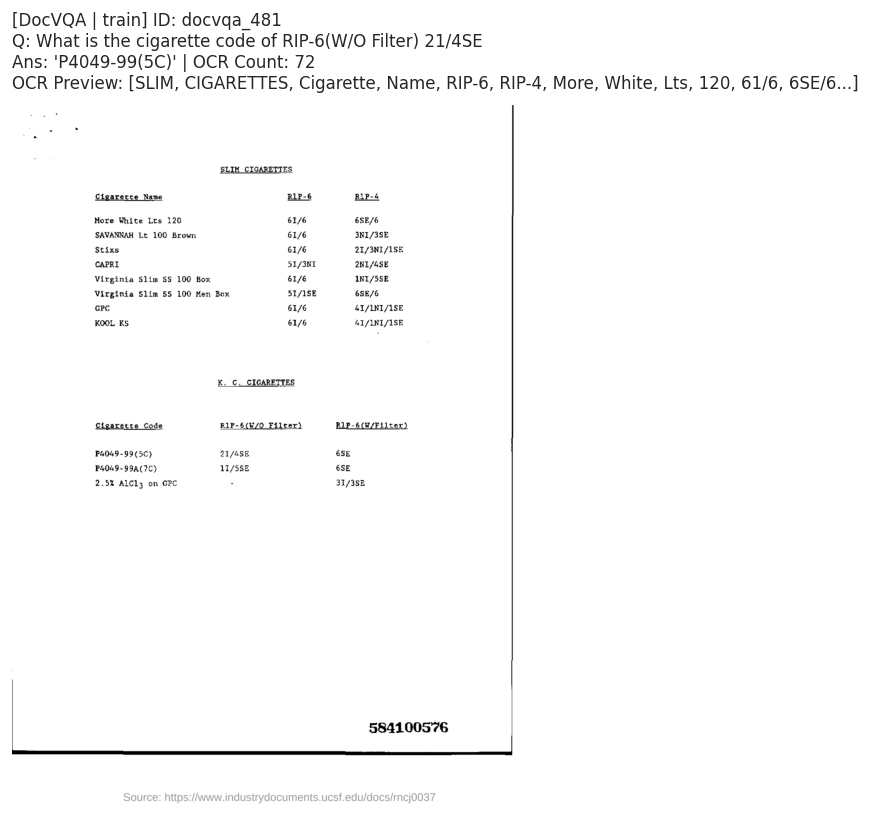

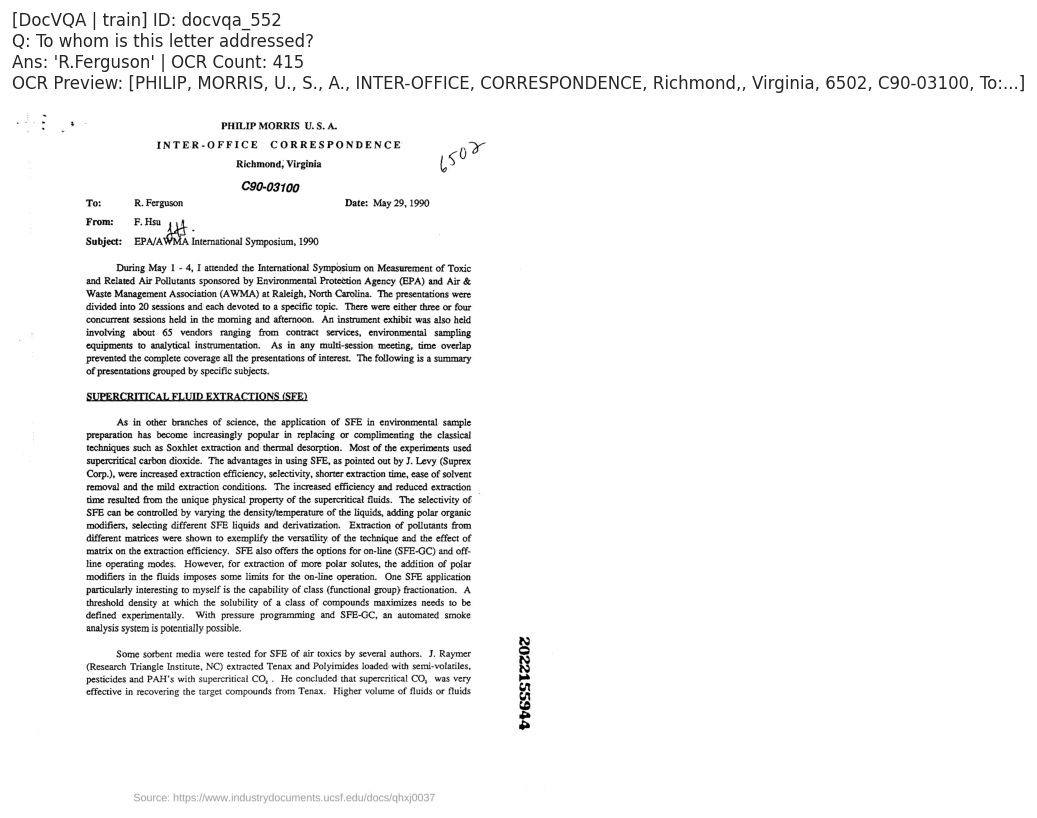

In [205]:
import io
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def to_pil_rgb(img_data):
    """Safely converts HF dataset image (PIL, dict, or raw bytes) to a clean RGB PIL Image."""
    if isinstance(img_data, dict):
        if img_data.get("bytes"):
            img = Image.open(io.BytesIO(img_data["bytes"]))
        elif img_data.get("path"):
            img = Image.open(img_data["path"])
        else:
            raise ValueError(f"Unsupported image dict format: {img_data.keys()}")
    elif isinstance(img_data, bytes):
        img = Image.open(io.BytesIO(img_data))
    elif isinstance(img_data, Image.Image):
        img = img_data
    else:
        # Array or other format
        img = Image.fromarray(np.array(img_data))
        
    return img.convert("RGB")

def inspect_abstract_samples_fast(df_taxonomy, hf_datasets, dataset_name="DocVQA", split="train", n_samples=3):
    ds_key = "docvqa-canonical" if dataset_name == "DocVQA" else "textvqa-canonical"
    hf_split = hf_datasets[ds_key][split]
    
    sub = df_taxonomy[
        (df_taxonomy["dataset"] == dataset_name) &
        (df_taxonomy["split"] == split) &
        (df_taxonomy["ocr_grounding"] == "Abstractive / Reasoning")
    ]
    
    if len(sub) == 0:
        print(f"No abstractive samples found for {dataset_name} ({split})")
        return
        
    sample_rows = sub.head(n_samples)
    target_ids = sample_rows["sample_id"].tolist()
    
    # Fast row lookup
    sample_id_col = hf_split["sample_id"]
    id_to_idx = {sid: idx for idx, sid in enumerate(sample_id_col) if sid in set(target_ids)}
    
    for sid in target_ids:
        if sid not in id_to_idx:
            continue
        idx = id_to_idx[sid]
        item = hf_split[idx]
        
        # Robust RGB PIL conversion
        pil_img = to_pil_rgb(item["image"])
        
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.imshow(pil_img)
        ax.axis("off")
        
        ocr_toks = item.get("ocr_tokens", [])
        if isinstance(ocr_toks, np.ndarray):
            ocr_toks = ocr_toks.tolist()
        ocr_preview = ", ".join([str(t) for t in ocr_toks[:12]]) + ("..." if len(ocr_toks) > 12 else "")
        
        plt.title(
            f"[{dataset_name} | {split}] ID: {item['sample_id']}\n"
            f"Q: {item['question']}\n"
            f"Ans: '{item['canonical_answer']}' | OCR Count: {len(ocr_toks)}\n"
            f"OCR Preview: [{ocr_preview}]",
            fontsize=10, loc="left", pad=10
        )
        plt.tight_layout()
        plt.show()

# Run visual inspections
inspect_abstract_samples_fast(df_taxonomy, datasets, dataset_name="TextVQA", split="train", n_samples=3)
inspect_abstract_samples_fast(df_taxonomy, datasets, dataset_name="DocVQA", split="train", n_samples=3)

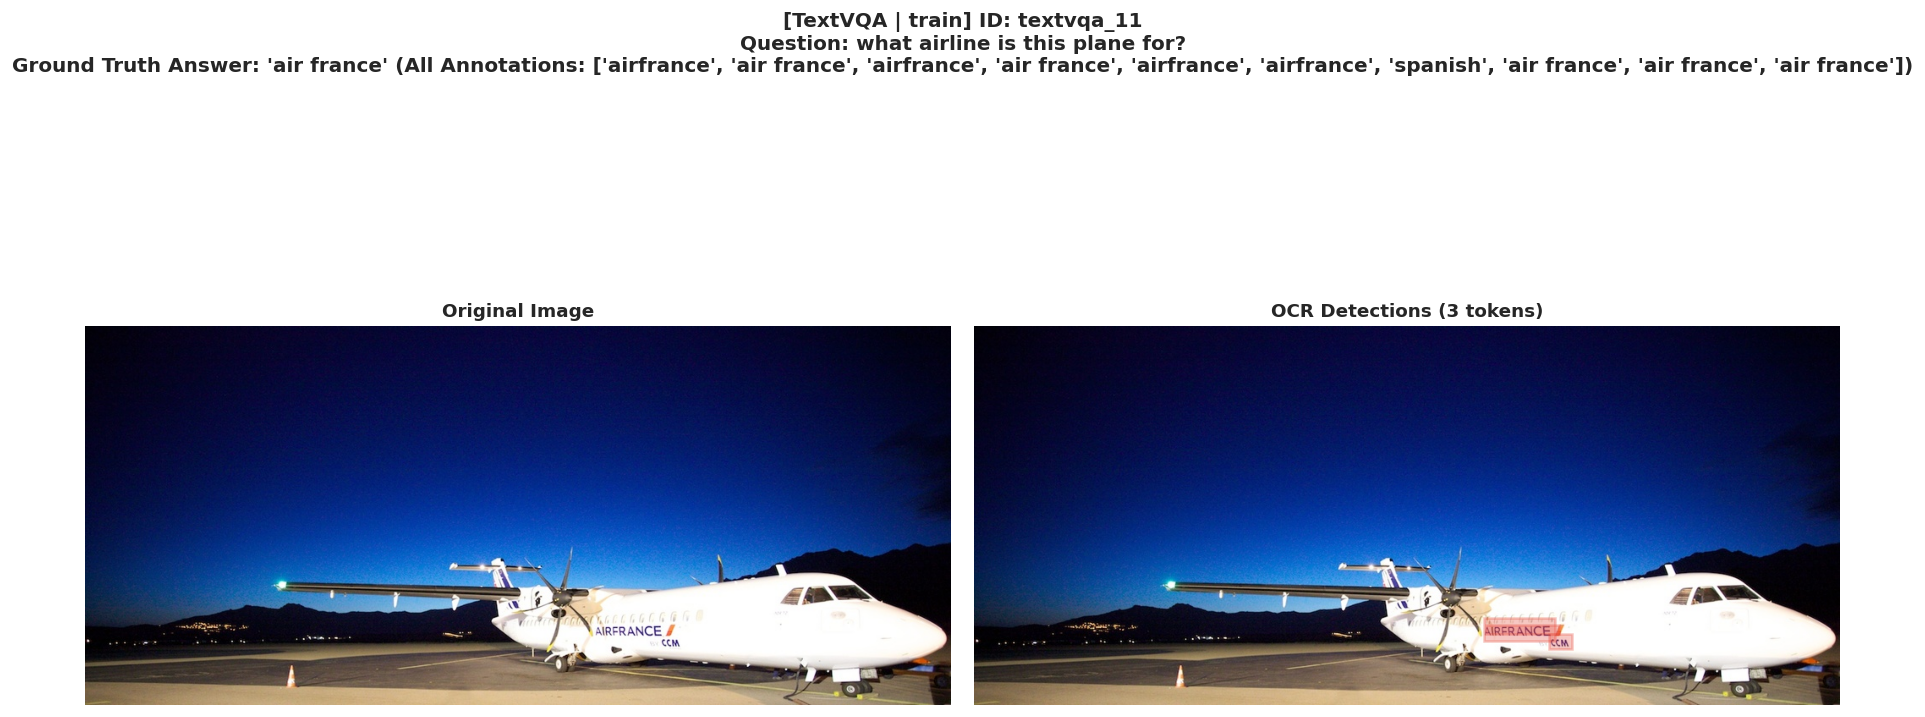

--- Full OCR Tokens for textvqa_11 (3 total) ---
['AIRFRANCE', 'CCM', 'IRFRANCE']



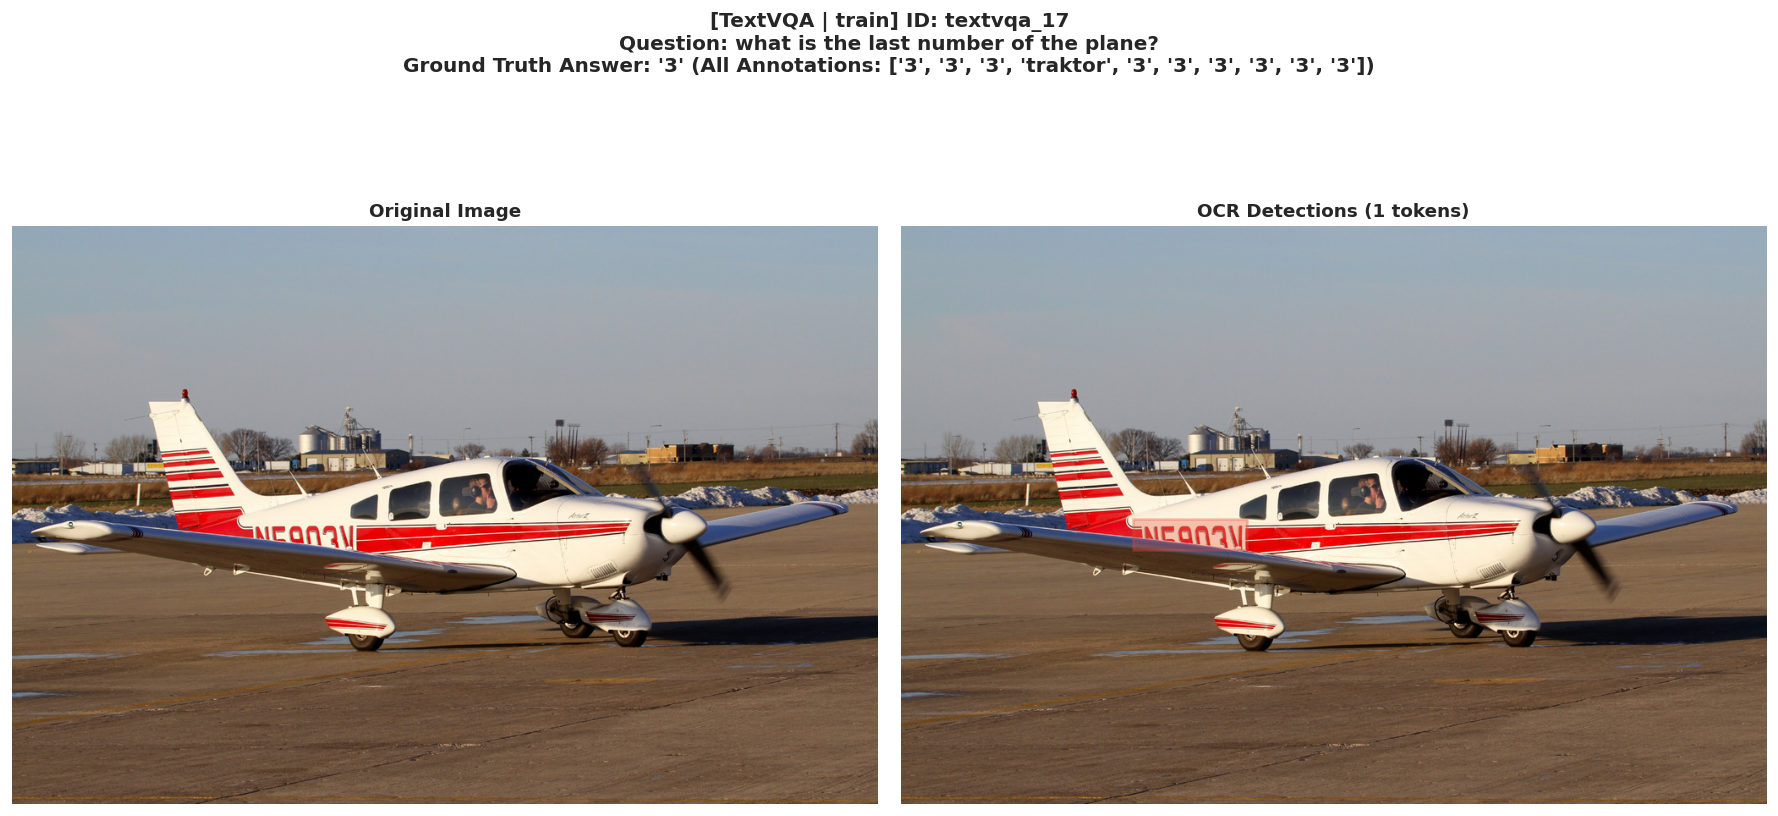

--- Full OCR Tokens for textvqa_17 (1 total) ---
['MEONaN']



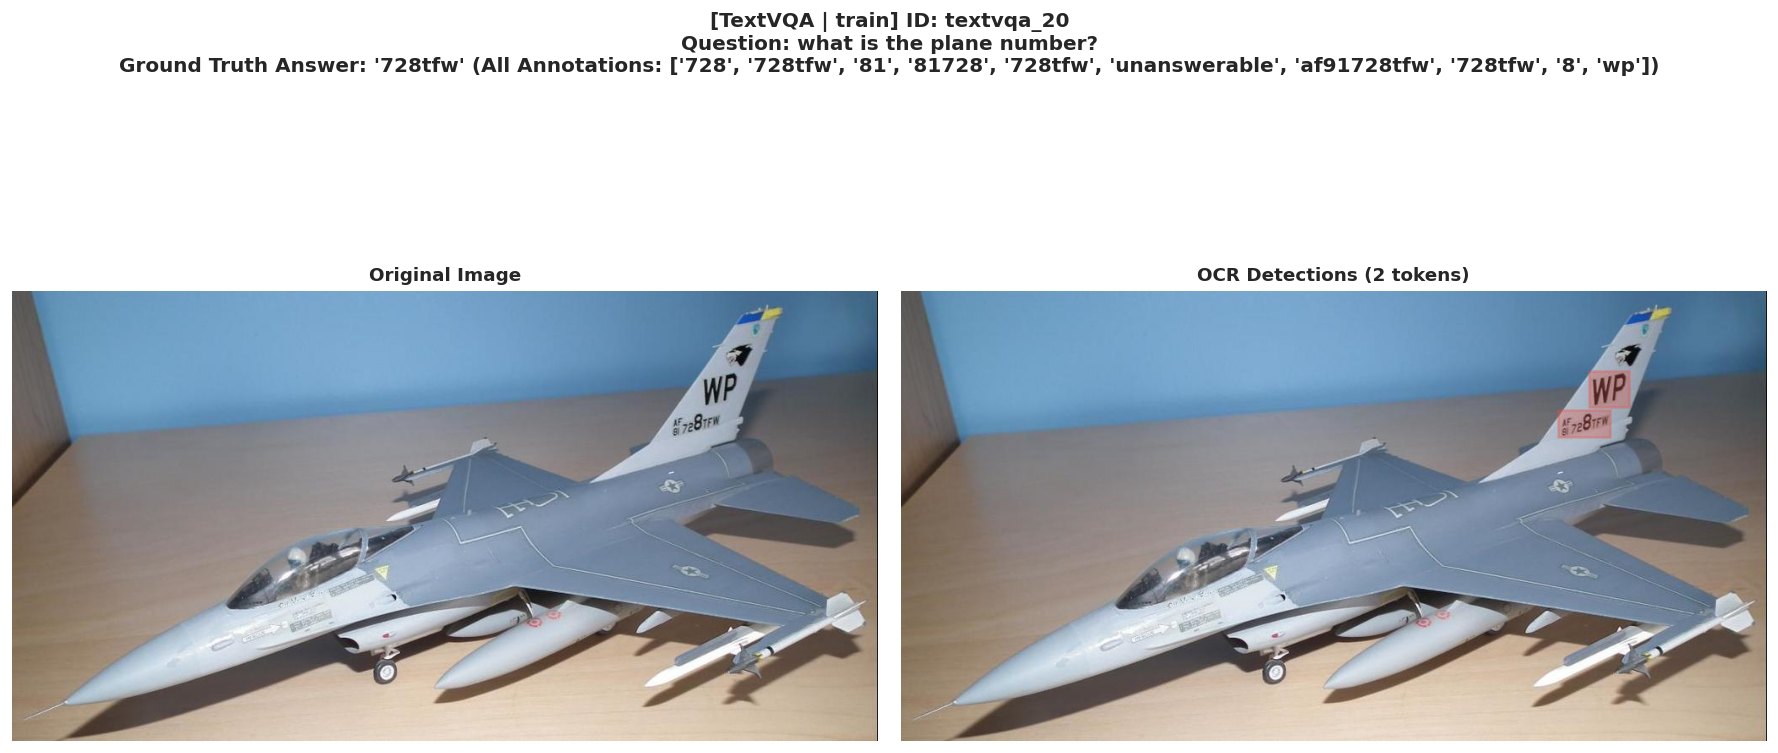

--- Full OCR Tokens for textvqa_20 (2 total) ---
['WP', 'AF7281FW']



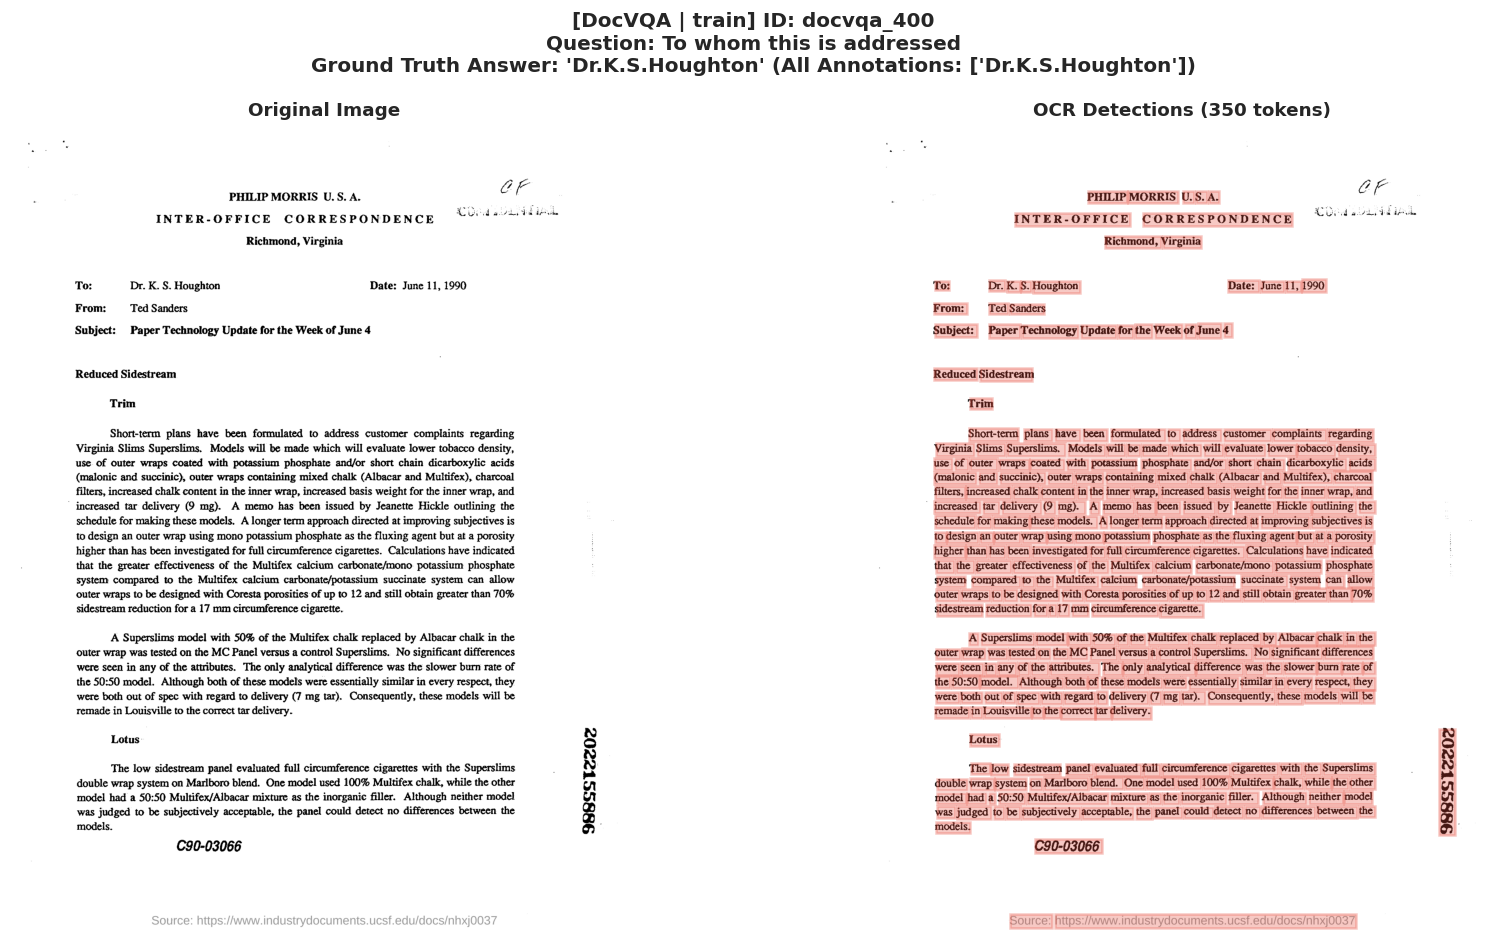

--- Full OCR Tokens for docvqa_400 (350 total) ---
['PHILIP', 'MORRIS', 'U.', 'S.', 'A.', 'INTER-OFFICE', 'CORRESPONDENCE', 'Richmond,', 'Virginia', 'To', 'Dr.', 'K.', 'S.', 'Houghton', 'Date:', 'June', '11,', '1990', 'From:', 'Ted', 'Sanders', 'Subject:', 'Paper', 'Technology', 'Update', 'for', 'the', 'Week', 'of', 'June', '4', 'Reduced', 'Sidestream', 'Trim', 'Short-term', 'plans', 'have', 'been', 'formulated', 'to', 'address', 'customer', 'complaints', 'regarding', 'Virginia', 'Slims', 'Superslims.', 'Models', 'will', 'be', 'made', 'which', 'will', 'evaluate', 'lower', 'tobacco', 'density,', 'use', 'of', 'outer', 'wraps', 'coated', 'with', 'potassium', 'phosphate', 'and/or', 'short', 'chain', 'dicarboxylic', 'acids', '(malonic', 'and', 'succinic),', 'outer', 'wraps', 'containing', 'mixed', 'chalk', '(Albacar', 'and', 'Multifex),', 'charcoal', 'filters,', 'increased', 'chalk', 'content', 'in', 'the', 'inner', 'wrap,', 'increased', 'basis', 'weight', 'for', 'the', 'inner', 'wrap,', 'a

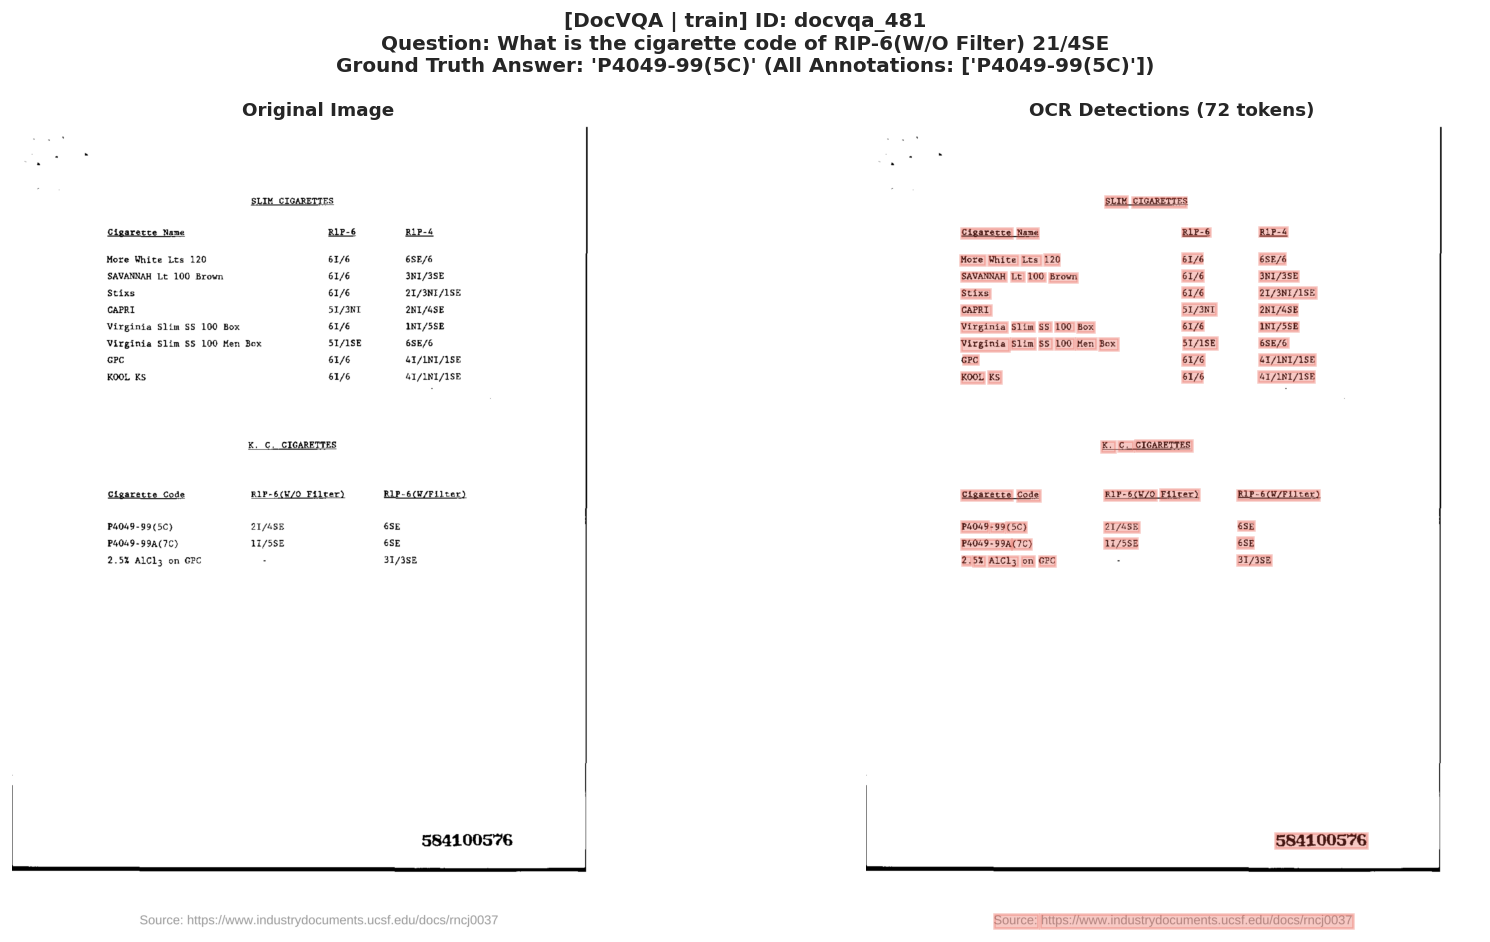

--- Full OCR Tokens for docvqa_481 (72 total) ---
['SLIM', 'CIGARETTES', 'Cigarette', 'Name', 'RIP-6', 'RIP-4', 'More', 'White', 'Lts', '120', '61/6', '6SE/6', 'SAVANNAH', 'Lt', '100', 'Brown', '61/6', '3NI/3SE', 'Stixs', '61/6', '21/3NI/1SE', 'CAPRI', '51/3NI', '2NI/4SE', 'Virginia', 'Slim', 'SS', '100', 'Box', '61/6', 'INI/5SE', 'Virginia', 'Slim', 'SS', '100', 'Men', 'Box', '51/1SE', '6SE/6', 'GPC', '61/6', '41/1NI/1SE', 'KOOL', 'KS', '61/6', '41/1NI/1SE', 'K.', 'C.', 'CIGARETTES', 'Cigarette', 'Code', 'RIP-6(W/0', 'Filter)', 'RIP-6(W/Filter)', 'P4049', '-99', '(5C)', '21/4SE', '6SE', 'P4049-99A', '(7C)', '11/5SE', '6SE', '2.', '5%', 'AlC13', 'on', 'GPC', '31/3SE', '584100576', 'Source:', 'https://www.industrydocuments.ucsf.edu/docs/rncj0037']



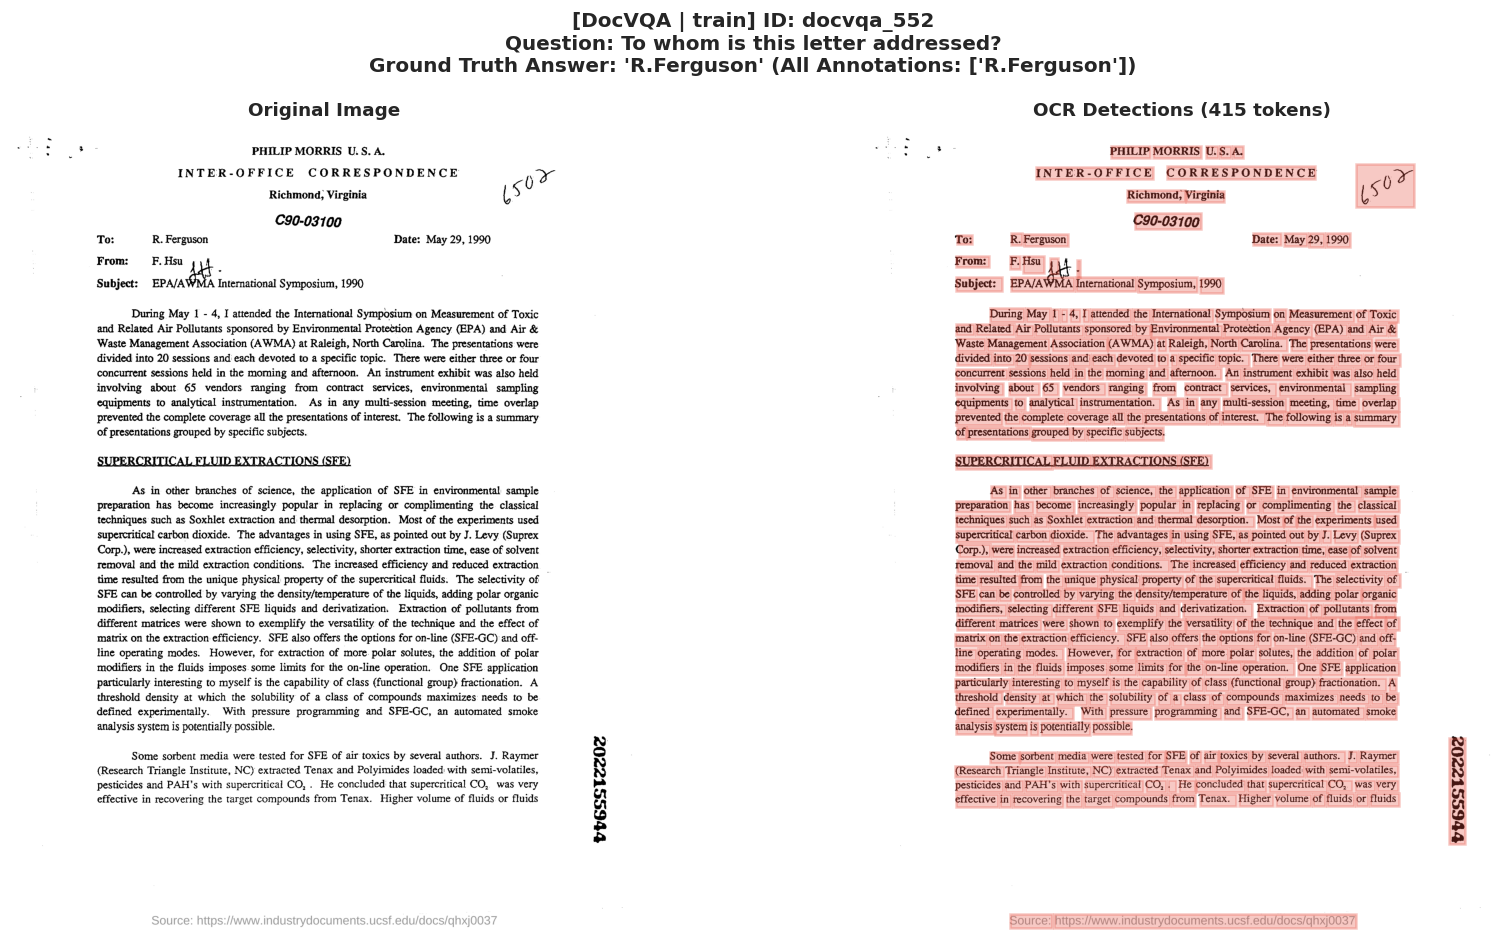

--- Full OCR Tokens for docvqa_552 (415 total) ---
['PHILIP', 'MORRIS', 'U.', 'S.', 'A.', 'INTER-OFFICE', 'CORRESPONDENCE', 'Richmond,', 'Virginia', '6502', 'C90-03100', 'To:', 'R.', 'Ferguson', 'Date:', 'May', '29,', '1990', 'From:', 'F.', 'HSU', '1', '-', 'Subject:', 'EPA/AWMA', 'International', 'Symposium,', '1990', 'During', 'May', '1', '-', '4,', 'I', 'attended', 'the', 'International', 'Symposium', 'on', 'Measurement', 'of', 'Toxic', 'and', 'Related', 'Air', 'Pollutants', 'sponsored', 'by', 'Environmental', 'Protection', 'Agency', '(EPA)', 'and', 'Air', '&', 'Waste', 'Management', 'Association', '(AWMA)', 'at', 'Raleigh,', 'North', 'Carolina.', 'The', 'presentations', 'were', 'divided', 'into', '20', 'sessions', 'and', 'each', 'devoted', 'to', 'a', 'specific', 'topic.', 'There', 'were', 'either', 'three', 'or', 'four', 'concurrent', 'sessions', 'held', 'in', 'the', 'morning', 'and', 'afternoon.', 'An', 'instrument', 'exhibit', 'was', 'also', 'held', 'involving', 'about', '65', 'v

In [209]:
# ==============================================================================
# RENDER IMAGES WITH OVERLAID OCR BOUNDING BOXES & FULL TOKENS (UNIFIED FIX)
# ==============================================================================
import io
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image

def render_sample_with_ocr_overlay(df_taxonomy, hf_datasets, dataset_name="TextVQA", split="train", n_samples=3):
    ds_key = "docvqa-canonical" if dataset_name == "DocVQA" else "textvqa-canonical"
    hf_split = hf_datasets[ds_key][split]
    
    sub = df_taxonomy[
        (df_taxonomy["dataset"] == dataset_name) &
        (df_taxonomy["split"] == split) &
        (df_taxonomy["ocr_grounding"] == "Abstractive / Reasoning")
    ]
    
    if len(sub) == 0:
        print(f"No abstractive samples found for {dataset_name} ({split})")
        return
        
    sample_rows = sub.head(n_samples)
    target_ids = sample_rows["sample_id"].tolist()
    
    sample_id_col = hf_split["sample_id"]
    id_to_idx = {sid: idx for idx, sid in enumerate(sample_id_col) if sid in set(target_ids)}
    
    for sid in target_ids:
        if sid not in id_to_idx:
            continue
        idx = id_to_idx[sid]
        item = hf_split[idx]
        
        pil_img = to_pil_rgb(item["image"])
        w_img, h_img = pil_img.size
        
        ocr_toks = item.get("ocr_tokens", [])
        ocr_boxes = item.get("ocr_boxes", [])
        if isinstance(ocr_toks, np.ndarray): ocr_toks = ocr_toks.tolist()
        if isinstance(ocr_boxes, np.ndarray): ocr_boxes = ocr_boxes.tolist()
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))
        
        # 1. Left: Original Image
        ax1.imshow(pil_img)
        ax1.axis("off")
        ax1.set_title("Original Image", fontsize=11, fontweight="bold")
        
        # 2. Right: Image with OCR Overlays
        ax2.imshow(pil_img)
        ax2.axis("off")
        ax2.set_title(f"OCR Detections ({len(ocr_toks)} tokens)", fontsize=11, fontweight="bold")
        
        # Unified coordinate conversion: [ymin, xmin, ymax, xmax] in [0, 1000]
        for box in ocr_boxes:
            if not box or len(box) < 4:
                continue
                
            ymin_norm, xmin_norm, ymax_norm, xmax_norm = box[0], box[1], box[2], box[3]
            
            # Map directly from [0, 1000] scale to image pixel dimensions
            xmin_px = (xmin_norm / 1000.0) * w_img
            xmax_px = (xmax_norm / 1000.0) * w_img
            ymin_px = (ymin_norm / 1000.0) * h_img
            ymax_px = (ymax_norm / 1000.0) * h_img
            
            bw = abs(xmax_px - xmin_px)
            bh = abs(ymax_px - ymin_px)
            xmin = min(xmin_px, xmax_px)
            ymin = min(ymin_px, ymax_px)
            
            rect = patches.Rectangle(
                (xmin, ymin), bw, bh,
                linewidth=1.5, edgecolor="#e74c3c", facecolor="#e74c3c", alpha=0.3
            )
            ax2.add_patch(rect)
            
        fig.suptitle(
            f"[{dataset_name} | {split}] ID: {item['sample_id']}\n"
            f"Question: {item['question']}\n"
            f"Ground Truth Answer: '{item['canonical_answer']}' (All Annotations: {item.get('answers', [])})",
            fontsize=12, y=0.98, fontweight="bold"
        )
        
        plt.tight_layout()
        plt.show()
        
        print(f"--- Full OCR Tokens for {item['sample_id']} ({len(ocr_toks)} total) ---")
        print(ocr_toks)
        print("=" * 90 + "\n")

# Run inspection
render_sample_with_ocr_overlay(df_taxonomy, datasets, dataset_name="TextVQA", split="train", n_samples=3)
render_sample_with_ocr_overlay(df_taxonomy, datasets, dataset_name="DocVQA", split="train", n_samples=3)

In [210]:
# ==============================================================================
# AUDIT: COMPREHENSIVE OCR BOUNDING BOX SANITY CHECK ACROSS ALL SPLITS
# ==============================================================================
import numpy as np
import pandas as pd

def audit_ocr_boxes_contract(split_dict):
    """
    Rigorously verifies:
      1. 1-to-1 cardinality between ocr_tokens and ocr_boxes
      2. Normalization bounds: all coords in [0, 1000]
      3. Non-degeneracy: ymin <= ymax and xmin <= xmax
      4. Geometric orientation: median word aspect ratio (width / height > 1.0)
    """
    audit_results = []
    
    for split_name, df_pl in split_dict.items():
        # Sample non-empty OCR rows
        df_sub = df_pl.filter(pl.col("ocr_tokens").list.len() > 0)
        
        total_boxes = 0
        oob_count = 0        # Out of bounds (< 0 or > 1000)
        inverted_y_cnt = 0   # ymin > ymax
        inverted_x_cnt = 0   # xmin > xmax
        cardinality_mismatch = 0
        aspect_ratios = []
        
        # Sample up to 1,000 queries per split for fast comprehensive audit
        sample_rows = df_sub.head(1000).select(["ocr_tokens", "ocr_boxes"]).to_dicts()
        
        for row in sample_rows:
            toks = row["ocr_tokens"]
            bxs = row["ocr_boxes"]
            
            if len(toks) != len(bxs):
                cardinality_mismatch += 1
                
            for b in bxs:
                if not b or len(b) < 4:
                    continue
                total_boxes += 1
                ymin, xmin, ymax, xmax = b[0], b[1], b[2], b[3]
                
                # Check [0, 1000] range
                if any(v < 0 or v > 1000 for v in [ymin, xmin, ymax, xmax]):
                    oob_count += 1
                # Check ordering
                if ymin > ymax:
                    inverted_y_cnt += 1
                if xmin > xmax:
                    inverted_x_cnt += 1
                    
                w = max(1, xmax - xmin)
                h = max(1, ymax - ymin)
                aspect_ratios.append(w / h)
                
        ar_arr = np.array(aspect_ratios)
        audit_results.append({
            "Split": split_name,
            "Audited Boxes": f"{total_boxes:,}",
            "Bounds [0, 1000]": f"{(1 - oob_count / max(1, total_boxes)) * 100:.2f}% Valid",
            "Y-Order (ymin <= ymax)": f"{(1 - inverted_y_cnt / max(1, total_boxes)) * 100:.2f}%",
            "X-Order (xmin <= xmax)": f"{(1 - inverted_x_cnt / max(1, total_boxes)) * 100:.2f}%",
            "Token-Box 1:1": "✓ 100%" if cardinality_mismatch == 0 else f"{cardinality_mismatch} errors",
            "Median Aspect Ratio (W/H)": f"{np.median(ar_arr):.2f} (Horizontal)" if len(ar_arr) else "N/A"
        })
        
    df_report = pd.DataFrame(audit_results)
    print("=" * 105)
    print("CROSSVQA CANONICAL OCR BOUNDING BOX AUDIT REPORT ([ymin, xmin, ymax, xmax] in [0, 1000])")
    print("=" * 105)
    display(df_report)

audit_ocr_boxes_contract(split_dict)

CROSSVQA CANONICAL OCR BOUNDING BOX AUDIT REPORT ([ymin, xmin, ymax, xmax] in [0, 1000])


,Split,Audited Boxes,"Bounds [0, 1000]",Y-Order (ymin <= ymax),X-Order (xmin <= xmax),Token-Box 1:1,Median Aspect Ratio (W/H)
0,textVQA_train,"6,415",100.00% Valid,100.00%,100.00%,✓ 100%,1.67 (Horizontal)
1,textVQA_val,"15,268",100.00% Valid,100.00%,100.00%,✓ 100%,2.06 (Horizontal)
2,textVQA_test,"15,107",100.00% Valid,100.00%,100.00%,✓ 100%,2.02 (Horizontal)
3,docVQA_train,"277,743",100.00% Valid,100.00%,100.00%,✓ 100%,2.81 (Horizontal)
4,docVQA_val,"181,970",100.00% Valid,100.00%,100.00%,✓ 100%,2.82 (Horizontal)
5,docVQA_test,"205,075",100.00% Valid,100.00%,100.00%,✓ 100%,2.80 (Horizontal)
